Publication adaptation: workspace labels and runtime paths have been renamed. Saved scientific results and embedded image bytes are retained from the recorded run; this source notebook has not been recomputed after that adaptation. Printed historical checksums describe that recorded run. Current released-file checksums are in the publication source map.

# Singh maps in Figure 2B's column-and-row layout

The authors explicitly requested this faceted display: metaclones in columns, days in rows. The complete atlas is split into readable column blocks, separately for WT, Dnmt3a and Npm1c. This authorization is specific to these maps; other manuscript panels remain separate. The shared Day-7 sample appears only under WT. Main comparison examples use the same visual grammar, with conditions in columns when the metaclone is fixed.

This is a display-only revision of the executed spatial atlas. No new expression access, embedding, assignments, tests or density normalization. Coordinates, cell/family support, fixed-bandwidth density, common numerical scale and sparse/empty handling are preserved. Figure 2B supplies the visual reference. The authors subsequently requested larger dots: foreground areas are doubled relative to that calibration, consistently across all grids. Gray context alone is rasterized; foreground points and labels are editable SVG vectors. Only identification, support and scale labels appear inside each figure. Full explanations belong in manuscript legends.

Use existing **chronoclone**, `/path/to/ChronoClone/.runtime/chronoclone`, Jupyter kernel **chronoclone** (existing Conda-managed installation, not modified). Exact versions and execution command are displayed below. Each output cell contains full snapshot selection, density calculation, faceted construction, one SVG/PNG output stem and display. `build_grid_notebook.py` generates the explicit cells; it does not generate figures itself.


In [1]:

from pathlib import Path
import sys,platform,json,hashlib,datetime,warnings
import numpy as np
import pandas as pd
import h5py,scipy,matplotlib
from scipy.ndimage import gaussian_filter,map_coordinates
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
from IPython.display import display
from PIL import Image
ROOT=Path('/path/to/ChronoClone')
OUT=ROOT/'analysis_workspace/singh/singh_figure2b_grid_layout_20260911'
ENV=Path('/path/to/ChronoClone/.runtime/chronoclone')
assert Path(sys.executable).parent.parent==ENV
for directory in ['panels','tables','reports']:(OUT/directory).mkdir(parents=True,exist_ok=True)
execution_command=f'{ENV}/bin/python {ROOT}/analysis_workspace/singh/singh_weinreb_style_umaps_20260911/execute_notebook.py {OUT}/0001_figure2b_grid_layout.ipynb'
environment={'name':'chronoclone','path':str(ENV),'manager':'existing Conda-managed environment; no mutation','kernel':'chronoclone',
             'python':platform.python_version(),'numpy':np.__version__,'pandas':pd.__version__,'scipy':scipy.__version__,
             'h5py':h5py.__version__,'matplotlib':matplotlib.__version__,'execution_command':execution_command}
display(environment)
plt.rcParams.update({'font.family':'DejaVu Sans','font.size':16,'axes.labelsize':16,'svg.fonttype':'none',
                     'savefig.facecolor':'white','figure.facecolor':'white','svg.hashsalt':'singh_weinreb_style_20260911'})
def sha256(path):
    digest=hashlib.sha256()
    with path.open('rb') as stream:
        for block in iter(lambda:stream.read(8*1024*1024),b''):digest.update(block)
    return digest.hexdigest()
CELL_SOURCE=ROOT/'analysis_workspace/singh/singh_reference_response_20260911/dynamics/tables/cells_resolved.csv'
MAP_SOURCE=ROOT/'data/processed/singh_strack/adata_valid_keep_all.h5ad'
PALETTE_SOURCE=ROOT/'analysis_workspace/singh/figure3_original_singh_landscape_20260811/tables/figure3_original_singh_clone_trajectory_umap_metaclone_label_positions.csv'
source_manifest=pd.DataFrame([{'source':str(p.relative_to(ROOT)),'bytes':p.stat().st_size,'sha256':sha256(p)} for p in [CELL_SOURCE,MAP_SOURCE,PALETTE_SOURCE]])
source_manifest.to_csv(OUT/'tables/source_manifest.csv',index=False)
display(source_manifest)

AUTHOR_NOTEBOOK=ROOT/'reference_workspace/notebooks/Figure2_klein_pace.ipynb'
AUTHOR_SVG=ROOT/'reference_workspace/Figure/fig2/panels/panel_2i_density_all_mc_flipped.svg'
OLD_ATLAS=ROOT/'analysis_workspace/singh/singh_landscape_expansion_20260911/atlas'
REFERENCE_AXES_WIDTH_PT=31 * 72 * (0.995-0.04) / (20+19*0.02)
assert abs(REFERENCE_AXES_WIDTH_PT-104.590775)<1e-6
style_sources=pd.DataFrame([{'source':str(p.relative_to(ROOT)),'bytes':p.stat().st_size,'sha256':sha256(p)}
    for p in [AUTHOR_NOTEBOOK,AUTHOR_SVG,OLD_ATLAS/'0001_metaclone_spatial_atlas.ipynb',OUT/'build_grid_notebook.py']])
style_sources.to_csv(OUT/'tables/style_source_manifest.csv',index=False)
display(style_sources)
print('Reference axes width (pt):',REFERENCE_AXES_WIDTH_PT)


{'name': 'chronoclone',
 'path': '/path/to/ChronoClone/.runtime/chronoclone',
 'manager': 'existing Conda-managed environment; no mutation',
 'kernel': 'chronoclone',
 'python': '3.11.15',
 'numpy': '2.4.6',
 'pandas': '2.3.3',
 'scipy': '1.17.1',
 'h5py': '3.16.0',
 'matplotlib': '3.11.0',
 'execution_command': '/path/to/ChronoClone/.runtime/chronoclone/bin/python /path/to/ChronoClone/analysis_workspace/singh/singh_weinreb_style_umaps_20260911/execute_notebook.py /path/to/ChronoClone/analysis_workspace/singh/singh_figure2b_grid_layout_20260911/0001_figure2b_grid_layout.ipynb'}

,source,bytes,sha256
0,analysis_workspace/singh/singh_reference_response_2...,3949086,1c6107fb429938c2c0ecdf2ef0119a606c3df10caea1c5...
1,data/processed/singh_strack/adata_valid_keep_a...,2859494374,9822997506ef9b2294c6c467cdb0fb6022c7a0c0e132f3...
2,analysis_workspace/singh/figure3_original_singh_lan...,3430,df1b27dc2c3440de24f4c345764d2da73a2bece5a461d9...


,source,bytes,sha256
0,reference_workspace/notebooks/Figure2_klein_pace.ipynb,5483967,8f653511b3de1c38f044438f6dff00970cbecf47f6e619...
1,reference_workspace/Figure/fig2/panels/panel_2i_den...,839150,147ddac7c553fc66fc6fdbfe3ed41312939cb038408ca7...
2,analysis_workspace/singh/singh_landscape_expansion_...,9320663,51eca4e3e3bdfd1596811cdf92b5a9d8956c82a2040cd3...
3,analysis_workspace/singh/singh_figure2b_grid_layout...,11704,b86c9255e23a6b43725265d5ad72cc17abc0848270e5b1...


Reference axes width (pt): 104.59077526987242


In [2]:

# Read only the cell registry, HDF5 observation index and stored embedding. Do not access X/raw/layers.
cells=pd.read_csv(CELL_SOURCE,keep_default_na=False)
assert cells.cell_id.is_unique and cells.clone.ne('').all() and cells.clone_resolved.eq(True).all()
with h5py.File(MAP_SOURCE,'r') as source:
    index_key=source['obs'].attrs['_index']
    if isinstance(index_key,bytes):index_key=index_key.decode()
    full_ids=pd.Index(source['obs'][index_key].asstr()[:],name='cell_id')
    full_umap=np.asarray(source['obsm']['X_umap'][:,:2],dtype=np.float64)
assert full_ids.is_unique and len(full_ids)==96662 and full_umap.shape==(len(full_ids),2)
assert np.isfinite(full_umap).all()
positions=full_ids.get_indexer(cells.cell_id)
assert (positions>=0).all()
cells['umap1']=full_umap[positions,0];cells['umap2']=full_umap[positions,1]
assert np.array_equal(cells[['umap1','umap2']].to_numpy(),full_umap[positions])
MC_IDS=sorted(cells.mc.astype(int).unique().tolist())
assert len(MC_IDS)==17
SNAPSHOTS=[('WT','D7'),('WT','D14'),('WT','D27'),('Npm1c','D14'),('Npm1c','D27'),('Dnmt3a','D14'),('Dnmt3a','D27')]
assert set(zip(cells.arm,cells.day))==set(SNAPSHOTS)
assert cells.groupby('clone').mc.nunique().max()==1
assert not cells[['umap1','umap2']].isna().any().any()
cells[['cell_id','mc','arm','day','clone','umap1','umap2']].to_csv(OUT/'tables/atlas_cell_coordinates.csv.gz',index=False)
BANDWIDTH=0.4
GRID_SIZE=256
PLOT_XLIM=(full_umap[:,0].min()-0.4,full_umap[:,0].max()+0.4)
PLOT_YLIM=(full_umap[:,1].min()-0.4,full_umap[:,1].max()+0.4)
X_EDGES=np.linspace(full_umap[:,0].min()-4*BANDWIDTH,full_umap[:,0].max()+4*BANDWIDTH,GRID_SIZE+1)
Y_EDGES=np.linspace(full_umap[:,1].min()-4*BANDWIDTH,full_umap[:,1].max()+4*BANDWIDTH,GRID_SIZE+1)
DX=float(X_EDGES[1]-X_EDGES[0]);DY=float(Y_EDGES[1]-Y_EDGES[0])
X_CENTERS=(X_EDGES[:-1]+X_EDGES[1:])/2;Y_CENTERS=(Y_EDGES[:-1]+Y_EDGES[1:])/2
MIN_DENSITY_CELLS=20;MIN_DENSITY_FAMILIES=3
SPARSE_COLOR='#234B6C'
MC_LABEL_COLORS={0:'#f77189',1:'#f8763b',2:'#d28e32',3:'#b79932',4:'#9ea231',5:'#7caa31',6:'#31b345',7:'#34b081',9:'#35ae9a',10:'#36acad',11:'#38aac1',12:'#3aa6dd',13:'#7699f4',15:'#b087f4',16:'#df6df4',17:'#f563d8',19:'#f66ab2'}
assert set(MC_LABEL_COLORS)==set(MC_IDS)
palette_source=pd.read_csv(PALETTE_SOURCE)
assert dict(zip(palette_source.metaclone.astype(int),palette_source.label_color))==MC_LABEL_COLORS
display(palette_source[['metaclone','label_color']])
design={'fullmap_cells':len(full_ids),'registry_cells':len(cells),'unique_families':cells.clone.nunique(),
        'metaclones':MC_IDS,'snapshots':SNAPSHOTS,'expected_maps':len(MC_IDS)*len(SNAPSHOTS),
        'plot_xlim':PLOT_XLIM,'plot_ylim':PLOT_YLIM,'bandwidth_umap_units':BANDWIDTH,
        'grid_size':[GRID_SIZE,GRID_SIZE],'grid_dx':DX,'grid_dy':DY,
        'density_min_cells':MIN_DENSITY_CELLS,'density_min_families':MIN_DENSITY_FAMILIES,
        'density_weighting':'each observed cell equally weighted within its MC/arm/day snapshot',
        'source_coordinate_identity':'exact float64 values from original X_umap in source row order',
        'mc_label_palette':MC_LABEL_COLORS,'font_family':'DejaVu Sans',
        'expression_matrix_accessed':False,'umap_refitted':False,'background_rasterized_only':True}
(OUT/'reports/design.json').write_text(json.dumps(design,indent=2))
display(design)
display(cells.groupby(['arm','day']).agg(cells=('cell_id','size'),families=('clone','nunique')).reset_index())


,metaclone,label_color
0,0,#f77189
1,1,#f8763b
2,2,#d28e32
3,3,#b79932
4,4,#9ea231
5,5,#7caa31
6,6,#31b345
7,7,#34b081
8,9,#35ae9a
9,10,#36acad


{'fullmap_cells': 96662,
 'registry_cells': 14896,
 'unique_families': 1516,
 'metaclones': [0, 1, 2, 3, 4, 5, 6, 7, 9, 10, 11, 12, 13, 15, 16, 17, 19],
 'snapshots': [('WT', 'D7'),
  ('WT', 'D14'),
  ('WT', 'D27'),
  ('Npm1c', 'D14'),
  ('Npm1c', 'D27'),
  ('Dnmt3a', 'D14'),
  ('Dnmt3a', 'D27')],
 'expected_maps': 119,
 'plot_xlim': (np.float64(-5.9684041976928714), np.float64(7.454280757904053)),
 'plot_ylim': (np.float64(-9.033657455444336), np.float64(5.982400798797608)),
 'bandwidth_umap_units': 0.4,
 'grid_size': [256, 256],
 'grid_dx': 0.06180736310780066,
 'grid_dy': 0.06803147755563188,
 'density_min_cells': 20,
 'density_min_families': 3,
 'density_weighting': 'each observed cell equally weighted within its MC/arm/day snapshot',
 'source_coordinate_identity': 'exact float64 values from original X_umap in source row order',
 'mc_label_palette': {0: '#f77189',
  1: '#f8763b',
  2: '#d28e32',
  3: '#b79932',
  4: '#9ea231',
  5: '#7caa31',
  6: '#31b345',
  7: '#34b081',
  9: '#

,arm,day,cells,families
0,Dnmt3a,D14,1525,506
1,Dnmt3a,D27,1838,98
2,Npm1c,D14,828,280
3,Npm1c,D27,3543,68
4,WT,D14,3515,1512
5,WT,D27,934,138
6,WT,D7,2713,1514


In [3]:

# Shared scale calculation only: this creates no figure. Each map recomputes its own density inline below.
scale_rows=[]
for mc in MC_IDS:
    for arm,day in SNAPSHOTS:
        selected=cells.loc[cells.mc.eq(mc)&cells.arm.eq(arm)&cells.day.eq(day)]
        n=len(selected);families=selected.clone.nunique()
        eligible=n>=MIN_DENSITY_CELLS and families>=MIN_DENSITY_FAMILIES
        if eligible:
            histogram,_,_=np.histogram2d(selected.umap1,selected.umap2,bins=(X_EDGES,Y_EDGES))
            density=gaussian_filter(histogram/n,sigma=(BANDWIDTH/DX,BANDWIDTH/DY),mode='constant',truncate=4)/(DX*DY)
            peak=float(density.max());mass=float(density.sum()*DX*DY)
            assert np.isfinite(density).all() and abs(mass-1)<0.003
        else:peak=np.nan;mass=np.nan
        scale_rows.append({'mc':mc,'arm':arm,'day':day,'cells':n,'families':families,
                           'representation':'density_colored_points' if eligible else ('raw_points_sparse' if n else 'empty'),
                           'density_peak':peak,'density_integrated_mass':mass})
scale_table=pd.DataFrame(scale_rows)
assert len(scale_table)==119 and not scale_table[['mc','arm','day']].duplicated().any()
DENSITY_MAX=float(scale_table.density_peak.max())
assert np.isfinite(DENSITY_MAX) and DENSITY_MAX>0
DENSITY_NORM=Normalize(vmin=0,vmax=DENSITY_MAX,clip=False)
scale_table.to_csv(OUT/'tables/snapshot_support_and_density_scale.csv',index=False)
design['density_common_vmin']=0;design['density_common_vmax']=DENSITY_MAX
(OUT/'reports/design.json').write_text(json.dumps(design,indent=2))
display(scale_table)
print('Common density color limits:',0,DENSITY_MAX)
print('Representation counts:',scale_table.representation.value_counts().to_dict())
render_records=[]

# Numeric display quantities and all cohort rows must remain unchanged from the previous atlas.
old_scale=pd.read_csv(OLD_ATLAS/'tables/snapshot_support_and_density_scale.csv')
pd.testing.assert_frame_equal(scale_table,old_scale,check_exact=False,rtol=1e-12,atol=1e-14)
old_coordinates=pd.read_csv(OLD_ATLAS/'tables/atlas_cell_coordinates.csv.gz')
pd.testing.assert_frame_equal(cells[['cell_id','mc','arm','day','clone','umap1','umap2']],old_coordinates,
                              check_exact=False,rtol=1e-14,atol=1e-14)
style={'reference_axes_width_pt':REFERENCE_AXES_WIDTH_PT,'foreground_reference_area_pt2':50,
       'background_reference_area_pt2':3.5,'foreground_reference_edge_pt':0.15,
       'foreground_alpha':0.8,'background_color':'#d3d3d3','font_family':'DejaVu Sans',
       'size_rule':'area = reference area * (actual equal-aspect axes width / reference width)^2',
       'density_calculation_and_common_scale_unchanged':True,'coordinate_limits_unchanged':True}
design.update(style)
(OUT/'reports/design.json').write_text(json.dumps(design,indent=2))
display(style)


,mc,arm,day,cells,families,representation,density_peak,density_integrated_mass
0,0,WT,D7,935,596,density_colored_points,0.114309,1.0
1,0,WT,D14,1039,593,density_colored_points,0.068940,1.0
2,0,WT,D27,0,0,empty,NaN,NaN
3,0,Npm1c,D14,218,90,density_colored_points,0.055300,1.0
4,0,Npm1c,D27,589,26,density_colored_points,0.086206,1.0
...,...,...,...,...,...,...,...,...
114,19,WT,D27,99,14,density_colored_points,0.089719,1.0
115,19,Npm1c,D14,0,0,empty,NaN,NaN
116,19,Npm1c,D27,64,3,density_colored_points,0.094650,1.0
117,19,Dnmt3a,D14,4,3,raw_points_sparse,NaN,NaN


Common density color limits: 0 0.34375069516975765
Representation counts: {'density_colored_points': 72, 'empty': 24, 'raw_points_sparse': 23}


{'reference_axes_width_pt': 104.59077526987242,
 'foreground_reference_area_pt2': 50,
 'background_reference_area_pt2': 3.5,
 'foreground_reference_edge_pt': 0.15,
 'foreground_alpha': 0.8,
 'background_color': '#d3d3d3',
 'font_family': 'DejaVu Sans',
 'size_rule': 'area = reference area * (actual equal-aspect axes width / reference width)^2',
 'density_calculation_and_common_scale_unchanged': True,
 'coordinate_limits_unchanged': True}

In [4]:

REFERENCE_FIGURE=ROOT/'analysis_workspace/manuscript/chronoclone_sister_clone_revision_20260911/figures/figure_2b_selected_metaclone_maps.svg'
assert REFERENCE_FIGURE.exists()
print('Visual reference:',REFERENCE_FIGURE,sha256(REFERENCE_FIGURE))
REFERENCE_SCRIPT=ROOT/'analysis_workspace/manuscript/chronoclone_manuscript_panel_styling_20260907/build_0001_figure2b_2d_2g_styling_notebook.py'
REFERENCE_BACKGROUND=ROOT/'analysis_workspace/weinreb/weinreb_metaclone_cohesion_power_20260819/tables/iseh2026_registered_cell_state_umap_source.csv'
ref=pd.read_csv(REFERENCE_BACKGROUND,usecols=['cell_id','UMAP1','UMAP2']).drop_duplicates('cell_id')
reference_aspect=(ref.UMAP1.max()-ref.UMAP1.min()+1.6)/(ref.UMAP2.max()-ref.UMAP2.min()+1.6)
# Actual Figure 2B GridSpec geometry, followed by equal-aspect adjustment.
reference_box_width=7.2*(.995-.10)/(5+4*.02)
reference_box_height=7.8*(.94-.025)/(2+.33)/(3-2*.04)
REFERENCE_AXES_WIDTH_PT=min(reference_box_width,reference_box_height*reference_aspect)*72
print('Current Figure 2B axes width (pt):',REFERENCE_AXES_WIDTH_PT)
MARKER_AREA_MULTIPLIER=2.0  # the authors' subsequent explicit request: make dots bigger.
print('Foreground diameter multiplier over Figure 2B:',np.sqrt(MARKER_AREA_MULTIPLIER))
display(pd.DataFrame([{'path':str(p.relative_to(ROOT)),'sha256':sha256(p)} for p in [REFERENCE_FIGURE,REFERENCE_SCRIPT,REFERENCE_BACKGROUND]]))
plt.rcParams.update({'font.family':'DejaVu Sans','font.size':13,'svg.hashsalt':'singh_figure2b_grid_20260911'})
grid_records=[];snapshot_records=[]
print('Authorized layout: metaclone columns, day rows; separate condition blocks; Day 7 only under WT.')


Visual reference: /path/to/ChronoClone/analysis_workspace/manuscript/chronoclone_sister_clone_revision_20260911/figures/figure_2b_selected_metaclone_maps.svg 7c1dd7887d7307d55c677c13bdf17d0ec546e4a1485a3754e514e6b0746af027
Current Figure 2B axes width (pt): 90.66692988852978
Foreground diameter multiplier over Figure 2B: 1.4142135623730951


,path,sha256
0,analysis_workspace/manuscript/chronoclone_sister_cl...,7c1dd7887d7307d55c677c13bdf17d0ec546e4a1485a37...
1,analysis_workspace/manuscript/chronoclone_manuscrip...,4626c25b3ffda4d5e7747a544aecb394eb428ffc930da9...
2,analysis_workspace/weinreb/weinreb_metaclone_cohesi...,4c5c532303ced39451a1de3bae67e6d75eb46358ee9450...


Authorized layout: metaclone columns, day rows; separate condition blocks; Day 7 only under WT.


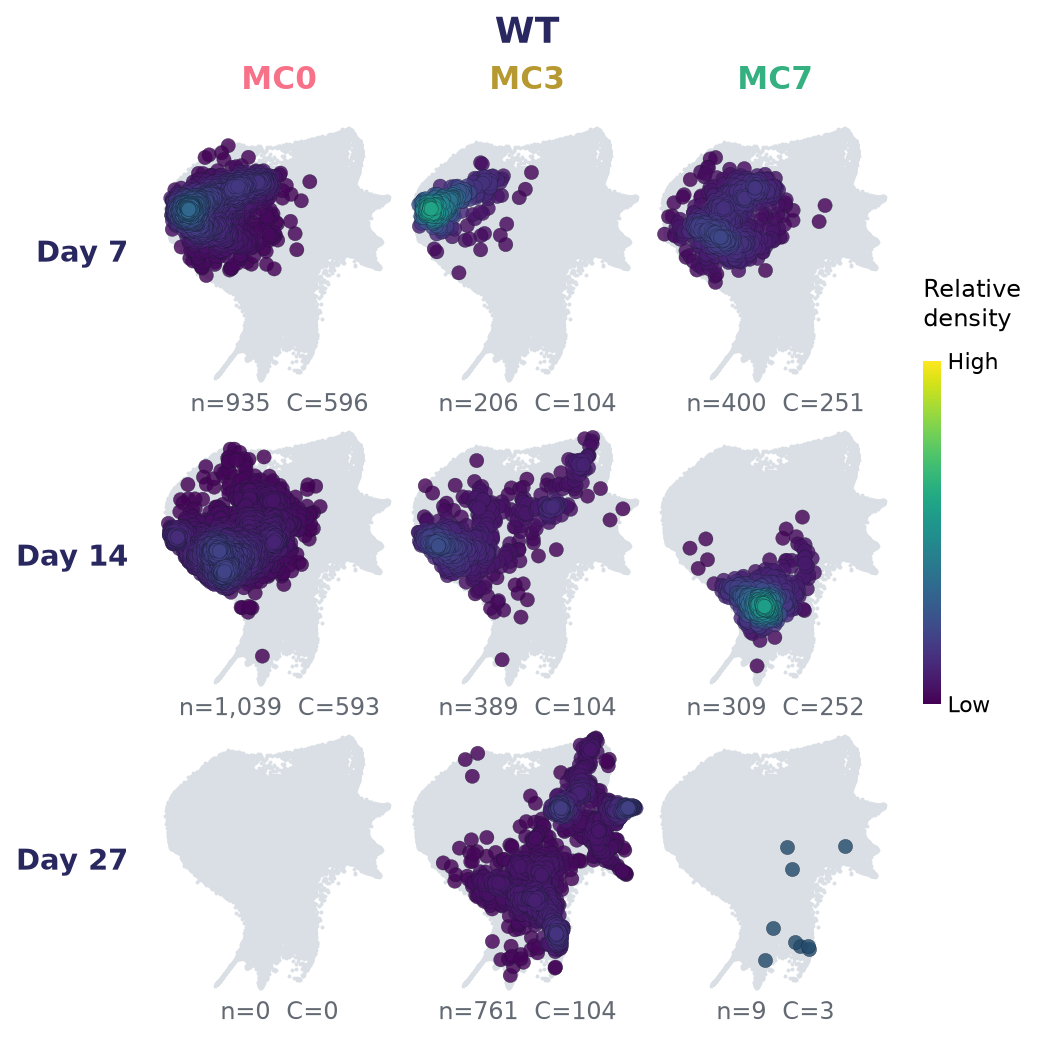

/path/to/ChronoClone/analysis_workspace/singh/singh_figure2b_grid_layout_20260911/panels/figure_5d_wt_histories_grid.svg


In [5]:

# One authorized faceted figure: all calculations and full construction visible.
stem='figure_5d_wt_histories_grid';metaclones=[0, 3, 7];arms=['WT'];days=['D7', 'D14', 'D27'];column_dimension='mc'
columns=metaclones if column_dimension=='mc' else arms
nc=len(columns);nr=len(days)
previous_figures=set(plt.get_fignums())
fw=1.05+1.55*nc+0.95;fh=0.8+1.90*nr
fig=plt.figure(figsize=(fw,fh),dpi=160,facecolor='white')
labels=[];axes_records=[]
group_label=arms[0] if column_dimension=='mc' else f'MC{metaclones[0]}'
labels.append(fig.text((1.05+1.55*nc/2)/fw,1-0.12/fh,group_label,
                      ha='center',va='top',fontsize=16,fontweight='bold',
                      color='#29275f' if column_dimension=='mc' else MC_LABEL_COLORS[metaclones[0]]))
for j,column in enumerate(columns):
    label=f'MC{column}' if column_dimension=='mc' else column
    labels.append(fig.text((1.05+1.55*(j+.5))/fw,1-0.43/fh,label,
                 ha='center',va='top',fontsize=14,fontweight='bold',
                 color=MC_LABEL_COLORS[column] if column_dimension=='mc' else '#29275f'))
for i,day in enumerate(days):
    bottom=fh-0.8-1.9*(i+1)+0.26
    labels.append(fig.text(0.88/fw,(bottom+.83)/fh,'Day '+day[1:],ha='right',va='center',
                          fontsize=13,fontweight='bold',color='#29275f'))
    for j,column in enumerate(columns):
        mc=column if column_dimension=='mc' else metaclones[0]
        arm=arms[0] if column_dimension=='mc' else column
        selected=cells.loc[cells.mc.eq(mc)&cells.arm.eq(arm)&cells.day.eq(day)].copy()
        n=len(selected);family_count=selected.clone.nunique()
        eligible=n>=MIN_DENSITY_CELLS and family_count>=MIN_DENSITY_FAMILIES
        locked=scale_table.loc[scale_table.mc.eq(mc)&scale_table.arm.eq(arm)&scale_table.day.eq(day)].iloc[0]
        assert (n,family_count)==(locked.cells,locked.families)
        if eligible:
            histogram,_,_=np.histogram2d(selected.umap1,selected.umap2,bins=(X_EDGES,Y_EDGES))
            density=gaussian_filter(histogram/n,sigma=(BANDWIDTH/DX,BANDWIDTH/DY),mode='constant',truncate=4)/(DX*DY)
            assert np.isclose(density.max(),locked.density_peak,rtol=1e-12)
            assert np.isclose(density.sum()*DX*DY,locked.density_integrated_mass,rtol=1e-12)
            point_density=map_coordinates(density,np.vstack(((selected.umap1-X_CENTERS[0])/DX,(selected.umap2-Y_CENTERS[0])/DY)),order=1,mode='nearest')
            order=np.argsort(point_density,kind='stable')
        else:
            point_density=None;order=np.arange(n)
        ax=fig.add_axes([(1.05+1.55*j)/fw,bottom/fh,1.52/fw,1.66/fh])
        ax.set_xlim(PLOT_XLIM);ax.set_ylim(PLOT_YLIM);ax.set_aspect('equal');ax.set_axis_off()
        fig.canvas.draw()
        width_pt=ax.get_window_extent().width/fig.dpi*72
        ratio=width_pt/REFERENCE_AXES_WIDTH_PT
        area=15*MARKER_AREA_MULTIPLIER*ratio**2;background_area=2.2*ratio**2;edge=.12*ratio
        assert np.isclose(np.sqrt(area)/width_pt,np.sqrt(15*MARKER_AREA_MULTIPLIER)/REFERENCE_AXES_WIDTH_PT,rtol=1e-12)
        ax.scatter(full_umap[:,0],full_umap[:,1],s=background_area,c='#d9dfe4',
                   linewidths=0,alpha=1,rasterized=True,zorder=0)
        if n:
            kwargs={'c':point_density[order],'cmap':'viridis','norm':DENSITY_NORM} if eligible else {'c':SPARSE_COLOR}
            ax.scatter(selected.umap1.to_numpy()[order],selected.umap2.to_numpy()[order],s=area,
                       **kwargs,edgecolors='#111827',linewidths=edge,alpha=.82,rasterized=False,zorder=2,clip_on=False)
        labels.append(fig.text((1.05+1.55*(j+.5))/fw,(bottom-.035)/fh,f'n={n:,}  C={family_count:,}',
                               ha='center',va='top',fontsize=11,color='#626972'))
        snapshot_records.append({'stem':stem,'mc':mc,'arm':arm,'day':day,'cells':n,'families':family_count,
                                 'representation':locked.representation,'marker_ratio':np.sqrt(area)/width_pt,
                                 'density_peak':float(locked.density_peak)})
        axes_records.append(ax)
# Integral common-scale key, not a separate analytical panel.
bar=fig.add_axes([(1.05+1.55*nc+.15)/fw,.32,.11/fw,.33])
cb=fig.colorbar(plt.cm.ScalarMappable(norm=DENSITY_NORM,cmap='viridis'),cax=bar)
cb.set_ticks([0,DENSITY_MAX]);cb.set_ticklabels(['Low','High']);cb.ax.tick_params(labelsize=10,length=0,pad=3)
cb.outline.set_visible(False)
labels.append(fig.text((1.05+1.55*nc+.15)/fw,.675,'Relative\ndensity',fontsize=11,ha='left',va='bottom'))
fig.canvas.draw()
renderer=fig.canvas.get_renderer()
for label in labels:
    box=label.get_window_extent(renderer)
    assert box.x0>=0 and box.y0>=0 and box.x1<=fig.bbox.width and box.y1<=fig.bbox.height,(stem,label.get_text(),box)
assert set(plt.get_fignums())-previous_figures=={fig.number}
svg=OUT/'panels'/f'{stem}.svg';png=svg.with_suffix('.png')
fig.savefig(svg);fig.savefig(png,dpi=240)
display(fig);plt.close(fig)
grid_records.append({'stem':stem,'columns':columns,'days':days,'column_dimension':column_dimension,
                     'width_in':fw,'height_in':fh,'svg_sha256':sha256(svg),'png_sha256':sha256(png)})
print(svg)


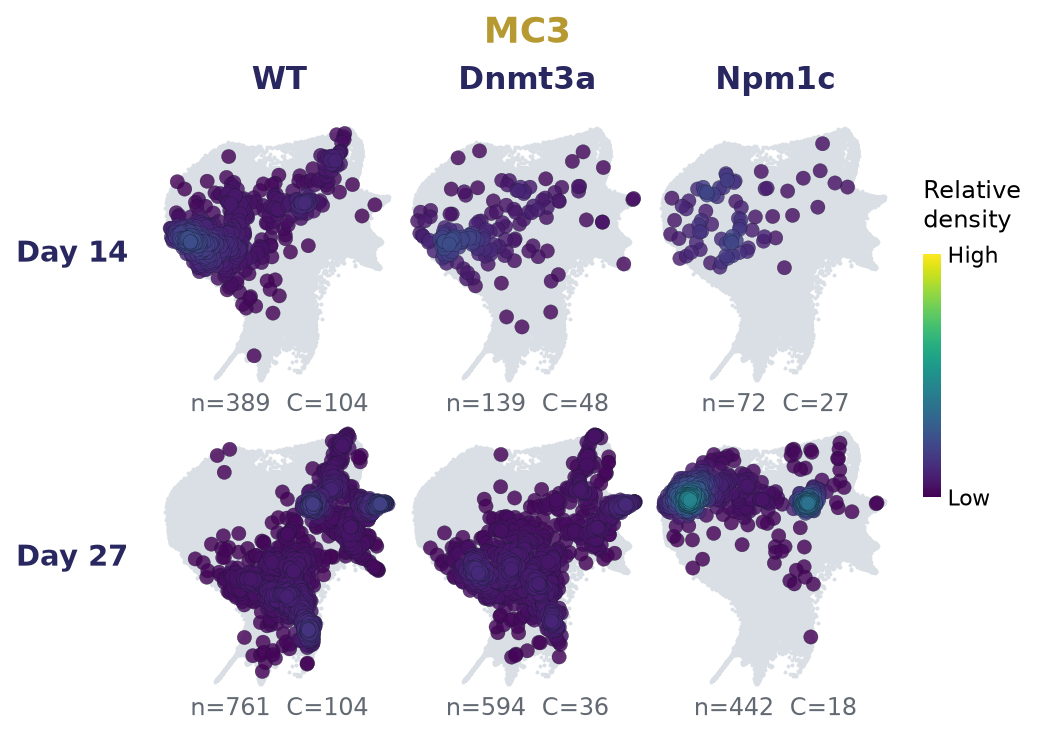

/path/to/ChronoClone/analysis_workspace/singh/singh_figure2b_grid_layout_20260911/panels/figure_6c_mc03_condition_grid.svg


In [6]:

# One authorized faceted figure: all calculations and full construction visible.
stem='figure_6c_mc03_condition_grid';metaclones=[3];arms=['WT', 'Dnmt3a', 'Npm1c'];days=['D14', 'D27'];column_dimension='arm'
columns=metaclones if column_dimension=='mc' else arms
nc=len(columns);nr=len(days)
previous_figures=set(plt.get_fignums())
fw=1.05+1.55*nc+0.95;fh=0.8+1.90*nr
fig=plt.figure(figsize=(fw,fh),dpi=160,facecolor='white')
labels=[];axes_records=[]
group_label=arms[0] if column_dimension=='mc' else f'MC{metaclones[0]}'
labels.append(fig.text((1.05+1.55*nc/2)/fw,1-0.12/fh,group_label,
                      ha='center',va='top',fontsize=16,fontweight='bold',
                      color='#29275f' if column_dimension=='mc' else MC_LABEL_COLORS[metaclones[0]]))
for j,column in enumerate(columns):
    label=f'MC{column}' if column_dimension=='mc' else column
    labels.append(fig.text((1.05+1.55*(j+.5))/fw,1-0.43/fh,label,
                 ha='center',va='top',fontsize=14,fontweight='bold',
                 color=MC_LABEL_COLORS[column] if column_dimension=='mc' else '#29275f'))
for i,day in enumerate(days):
    bottom=fh-0.8-1.9*(i+1)+0.26
    labels.append(fig.text(0.88/fw,(bottom+.83)/fh,'Day '+day[1:],ha='right',va='center',
                          fontsize=13,fontweight='bold',color='#29275f'))
    for j,column in enumerate(columns):
        mc=column if column_dimension=='mc' else metaclones[0]
        arm=arms[0] if column_dimension=='mc' else column
        selected=cells.loc[cells.mc.eq(mc)&cells.arm.eq(arm)&cells.day.eq(day)].copy()
        n=len(selected);family_count=selected.clone.nunique()
        eligible=n>=MIN_DENSITY_CELLS and family_count>=MIN_DENSITY_FAMILIES
        locked=scale_table.loc[scale_table.mc.eq(mc)&scale_table.arm.eq(arm)&scale_table.day.eq(day)].iloc[0]
        assert (n,family_count)==(locked.cells,locked.families)
        if eligible:
            histogram,_,_=np.histogram2d(selected.umap1,selected.umap2,bins=(X_EDGES,Y_EDGES))
            density=gaussian_filter(histogram/n,sigma=(BANDWIDTH/DX,BANDWIDTH/DY),mode='constant',truncate=4)/(DX*DY)
            assert np.isclose(density.max(),locked.density_peak,rtol=1e-12)
            assert np.isclose(density.sum()*DX*DY,locked.density_integrated_mass,rtol=1e-12)
            point_density=map_coordinates(density,np.vstack(((selected.umap1-X_CENTERS[0])/DX,(selected.umap2-Y_CENTERS[0])/DY)),order=1,mode='nearest')
            order=np.argsort(point_density,kind='stable')
        else:
            point_density=None;order=np.arange(n)
        ax=fig.add_axes([(1.05+1.55*j)/fw,bottom/fh,1.52/fw,1.66/fh])
        ax.set_xlim(PLOT_XLIM);ax.set_ylim(PLOT_YLIM);ax.set_aspect('equal');ax.set_axis_off()
        fig.canvas.draw()
        width_pt=ax.get_window_extent().width/fig.dpi*72
        ratio=width_pt/REFERENCE_AXES_WIDTH_PT
        area=15*MARKER_AREA_MULTIPLIER*ratio**2;background_area=2.2*ratio**2;edge=.12*ratio
        assert np.isclose(np.sqrt(area)/width_pt,np.sqrt(15*MARKER_AREA_MULTIPLIER)/REFERENCE_AXES_WIDTH_PT,rtol=1e-12)
        ax.scatter(full_umap[:,0],full_umap[:,1],s=background_area,c='#d9dfe4',
                   linewidths=0,alpha=1,rasterized=True,zorder=0)
        if n:
            kwargs={'c':point_density[order],'cmap':'viridis','norm':DENSITY_NORM} if eligible else {'c':SPARSE_COLOR}
            ax.scatter(selected.umap1.to_numpy()[order],selected.umap2.to_numpy()[order],s=area,
                       **kwargs,edgecolors='#111827',linewidths=edge,alpha=.82,rasterized=False,zorder=2,clip_on=False)
        labels.append(fig.text((1.05+1.55*(j+.5))/fw,(bottom-.035)/fh,f'n={n:,}  C={family_count:,}',
                               ha='center',va='top',fontsize=11,color='#626972'))
        snapshot_records.append({'stem':stem,'mc':mc,'arm':arm,'day':day,'cells':n,'families':family_count,
                                 'representation':locked.representation,'marker_ratio':np.sqrt(area)/width_pt,
                                 'density_peak':float(locked.density_peak)})
        axes_records.append(ax)
# Integral common-scale key, not a separate analytical panel.
bar=fig.add_axes([(1.05+1.55*nc+.15)/fw,.32,.11/fw,.33])
cb=fig.colorbar(plt.cm.ScalarMappable(norm=DENSITY_NORM,cmap='viridis'),cax=bar)
cb.set_ticks([0,DENSITY_MAX]);cb.set_ticklabels(['Low','High']);cb.ax.tick_params(labelsize=10,length=0,pad=3)
cb.outline.set_visible(False)
labels.append(fig.text((1.05+1.55*nc+.15)/fw,.675,'Relative\ndensity',fontsize=11,ha='left',va='bottom'))
fig.canvas.draw()
renderer=fig.canvas.get_renderer()
for label in labels:
    box=label.get_window_extent(renderer)
    assert box.x0>=0 and box.y0>=0 and box.x1<=fig.bbox.width and box.y1<=fig.bbox.height,(stem,label.get_text(),box)
assert set(plt.get_fignums())-previous_figures=={fig.number}
svg=OUT/'panels'/f'{stem}.svg';png=svg.with_suffix('.png')
fig.savefig(svg);fig.savefig(png,dpi=240)
display(fig);plt.close(fig)
grid_records.append({'stem':stem,'columns':columns,'days':days,'column_dimension':column_dimension,
                     'width_in':fw,'height_in':fh,'svg_sha256':sha256(svg),'png_sha256':sha256(png)})
print(svg)


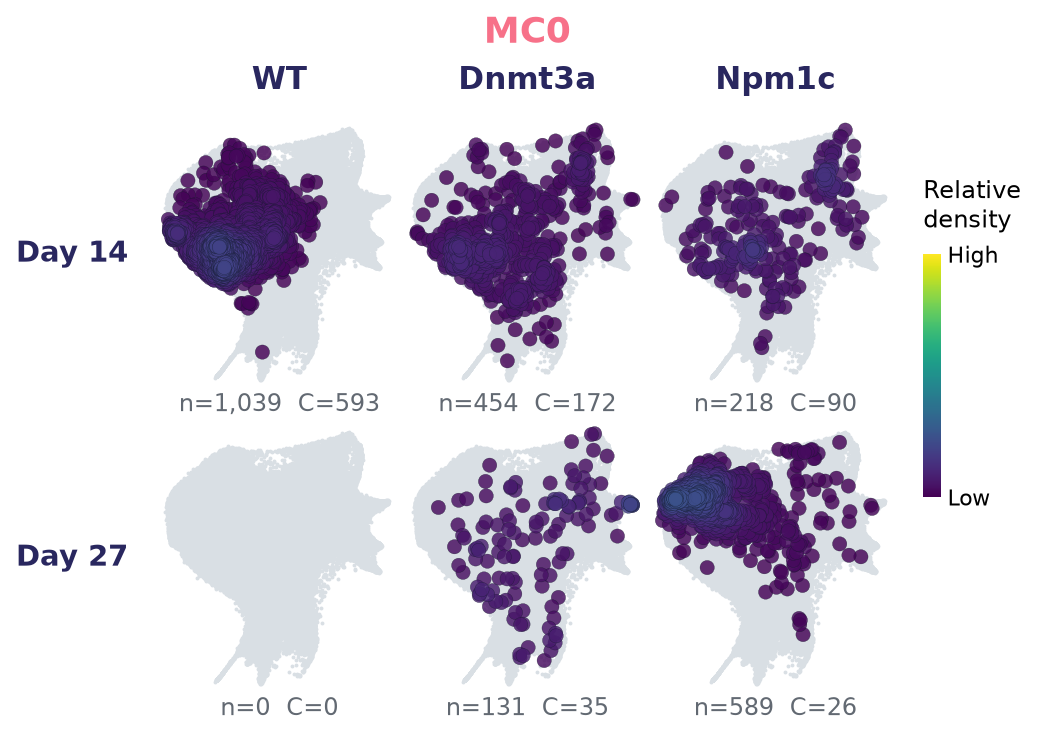

/path/to/ChronoClone/analysis_workspace/singh/singh_figure2b_grid_layout_20260911/panels/figure_6g_mc00_condition_grid.svg


In [7]:

# One authorized faceted figure: all calculations and full construction visible.
stem='figure_6g_mc00_condition_grid';metaclones=[0];arms=['WT', 'Dnmt3a', 'Npm1c'];days=['D14', 'D27'];column_dimension='arm'
columns=metaclones if column_dimension=='mc' else arms
nc=len(columns);nr=len(days)
previous_figures=set(plt.get_fignums())
fw=1.05+1.55*nc+0.95;fh=0.8+1.90*nr
fig=plt.figure(figsize=(fw,fh),dpi=160,facecolor='white')
labels=[];axes_records=[]
group_label=arms[0] if column_dimension=='mc' else f'MC{metaclones[0]}'
labels.append(fig.text((1.05+1.55*nc/2)/fw,1-0.12/fh,group_label,
                      ha='center',va='top',fontsize=16,fontweight='bold',
                      color='#29275f' if column_dimension=='mc' else MC_LABEL_COLORS[metaclones[0]]))
for j,column in enumerate(columns):
    label=f'MC{column}' if column_dimension=='mc' else column
    labels.append(fig.text((1.05+1.55*(j+.5))/fw,1-0.43/fh,label,
                 ha='center',va='top',fontsize=14,fontweight='bold',
                 color=MC_LABEL_COLORS[column] if column_dimension=='mc' else '#29275f'))
for i,day in enumerate(days):
    bottom=fh-0.8-1.9*(i+1)+0.26
    labels.append(fig.text(0.88/fw,(bottom+.83)/fh,'Day '+day[1:],ha='right',va='center',
                          fontsize=13,fontweight='bold',color='#29275f'))
    for j,column in enumerate(columns):
        mc=column if column_dimension=='mc' else metaclones[0]
        arm=arms[0] if column_dimension=='mc' else column
        selected=cells.loc[cells.mc.eq(mc)&cells.arm.eq(arm)&cells.day.eq(day)].copy()
        n=len(selected);family_count=selected.clone.nunique()
        eligible=n>=MIN_DENSITY_CELLS and family_count>=MIN_DENSITY_FAMILIES
        locked=scale_table.loc[scale_table.mc.eq(mc)&scale_table.arm.eq(arm)&scale_table.day.eq(day)].iloc[0]
        assert (n,family_count)==(locked.cells,locked.families)
        if eligible:
            histogram,_,_=np.histogram2d(selected.umap1,selected.umap2,bins=(X_EDGES,Y_EDGES))
            density=gaussian_filter(histogram/n,sigma=(BANDWIDTH/DX,BANDWIDTH/DY),mode='constant',truncate=4)/(DX*DY)
            assert np.isclose(density.max(),locked.density_peak,rtol=1e-12)
            assert np.isclose(density.sum()*DX*DY,locked.density_integrated_mass,rtol=1e-12)
            point_density=map_coordinates(density,np.vstack(((selected.umap1-X_CENTERS[0])/DX,(selected.umap2-Y_CENTERS[0])/DY)),order=1,mode='nearest')
            order=np.argsort(point_density,kind='stable')
        else:
            point_density=None;order=np.arange(n)
        ax=fig.add_axes([(1.05+1.55*j)/fw,bottom/fh,1.52/fw,1.66/fh])
        ax.set_xlim(PLOT_XLIM);ax.set_ylim(PLOT_YLIM);ax.set_aspect('equal');ax.set_axis_off()
        fig.canvas.draw()
        width_pt=ax.get_window_extent().width/fig.dpi*72
        ratio=width_pt/REFERENCE_AXES_WIDTH_PT
        area=15*MARKER_AREA_MULTIPLIER*ratio**2;background_area=2.2*ratio**2;edge=.12*ratio
        assert np.isclose(np.sqrt(area)/width_pt,np.sqrt(15*MARKER_AREA_MULTIPLIER)/REFERENCE_AXES_WIDTH_PT,rtol=1e-12)
        ax.scatter(full_umap[:,0],full_umap[:,1],s=background_area,c='#d9dfe4',
                   linewidths=0,alpha=1,rasterized=True,zorder=0)
        if n:
            kwargs={'c':point_density[order],'cmap':'viridis','norm':DENSITY_NORM} if eligible else {'c':SPARSE_COLOR}
            ax.scatter(selected.umap1.to_numpy()[order],selected.umap2.to_numpy()[order],s=area,
                       **kwargs,edgecolors='#111827',linewidths=edge,alpha=.82,rasterized=False,zorder=2,clip_on=False)
        labels.append(fig.text((1.05+1.55*(j+.5))/fw,(bottom-.035)/fh,f'n={n:,}  C={family_count:,}',
                               ha='center',va='top',fontsize=11,color='#626972'))
        snapshot_records.append({'stem':stem,'mc':mc,'arm':arm,'day':day,'cells':n,'families':family_count,
                                 'representation':locked.representation,'marker_ratio':np.sqrt(area)/width_pt,
                                 'density_peak':float(locked.density_peak)})
        axes_records.append(ax)
# Integral common-scale key, not a separate analytical panel.
bar=fig.add_axes([(1.05+1.55*nc+.15)/fw,.32,.11/fw,.33])
cb=fig.colorbar(plt.cm.ScalarMappable(norm=DENSITY_NORM,cmap='viridis'),cax=bar)
cb.set_ticks([0,DENSITY_MAX]);cb.set_ticklabels(['Low','High']);cb.ax.tick_params(labelsize=10,length=0,pad=3)
cb.outline.set_visible(False)
labels.append(fig.text((1.05+1.55*nc+.15)/fw,.675,'Relative\ndensity',fontsize=11,ha='left',va='bottom'))
fig.canvas.draw()
renderer=fig.canvas.get_renderer()
for label in labels:
    box=label.get_window_extent(renderer)
    assert box.x0>=0 and box.y0>=0 and box.x1<=fig.bbox.width and box.y1<=fig.bbox.height,(stem,label.get_text(),box)
assert set(plt.get_fignums())-previous_figures=={fig.number}
svg=OUT/'panels'/f'{stem}.svg';png=svg.with_suffix('.png')
fig.savefig(svg);fig.savefig(png,dpi=240)
display(fig);plt.close(fig)
grid_records.append({'stem':stem,'columns':columns,'days':days,'column_dimension':column_dimension,
                     'width_in':fw,'height_in':fh,'svg_sha256':sha256(svg),'png_sha256':sha256(png)})
print(svg)


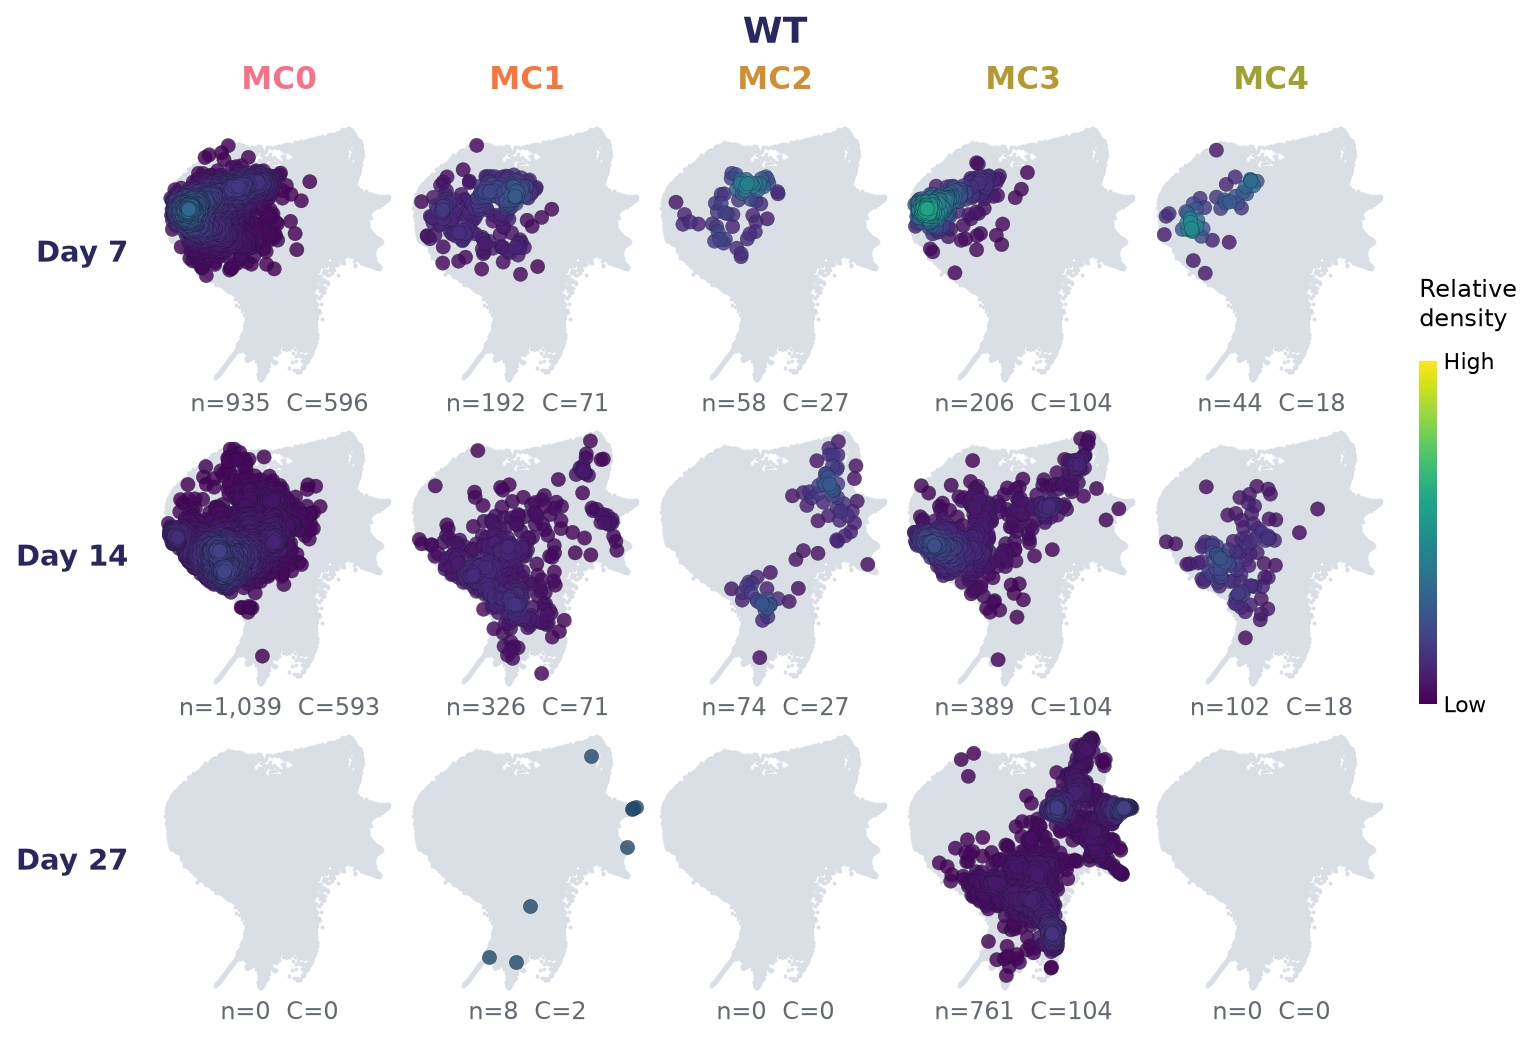

/path/to/ChronoClone/analysis_workspace/singh/singh_figure2b_grid_layout_20260911/panels/atlas_wt_block_01.svg


In [8]:

# One authorized faceted figure: all calculations and full construction visible.
stem='atlas_wt_block_01';metaclones=[0, 1, 2, 3, 4];arms=['WT'];days=['D7', 'D14', 'D27'];column_dimension='mc'
columns=metaclones if column_dimension=='mc' else arms
nc=len(columns);nr=len(days)
previous_figures=set(plt.get_fignums())
fw=1.05+1.55*nc+0.95;fh=0.8+1.90*nr
fig=plt.figure(figsize=(fw,fh),dpi=160,facecolor='white')
labels=[];axes_records=[]
group_label=arms[0] if column_dimension=='mc' else f'MC{metaclones[0]}'
labels.append(fig.text((1.05+1.55*nc/2)/fw,1-0.12/fh,group_label,
                      ha='center',va='top',fontsize=16,fontweight='bold',
                      color='#29275f' if column_dimension=='mc' else MC_LABEL_COLORS[metaclones[0]]))
for j,column in enumerate(columns):
    label=f'MC{column}' if column_dimension=='mc' else column
    labels.append(fig.text((1.05+1.55*(j+.5))/fw,1-0.43/fh,label,
                 ha='center',va='top',fontsize=14,fontweight='bold',
                 color=MC_LABEL_COLORS[column] if column_dimension=='mc' else '#29275f'))
for i,day in enumerate(days):
    bottom=fh-0.8-1.9*(i+1)+0.26
    labels.append(fig.text(0.88/fw,(bottom+.83)/fh,'Day '+day[1:],ha='right',va='center',
                          fontsize=13,fontweight='bold',color='#29275f'))
    for j,column in enumerate(columns):
        mc=column if column_dimension=='mc' else metaclones[0]
        arm=arms[0] if column_dimension=='mc' else column
        selected=cells.loc[cells.mc.eq(mc)&cells.arm.eq(arm)&cells.day.eq(day)].copy()
        n=len(selected);family_count=selected.clone.nunique()
        eligible=n>=MIN_DENSITY_CELLS and family_count>=MIN_DENSITY_FAMILIES
        locked=scale_table.loc[scale_table.mc.eq(mc)&scale_table.arm.eq(arm)&scale_table.day.eq(day)].iloc[0]
        assert (n,family_count)==(locked.cells,locked.families)
        if eligible:
            histogram,_,_=np.histogram2d(selected.umap1,selected.umap2,bins=(X_EDGES,Y_EDGES))
            density=gaussian_filter(histogram/n,sigma=(BANDWIDTH/DX,BANDWIDTH/DY),mode='constant',truncate=4)/(DX*DY)
            assert np.isclose(density.max(),locked.density_peak,rtol=1e-12)
            assert np.isclose(density.sum()*DX*DY,locked.density_integrated_mass,rtol=1e-12)
            point_density=map_coordinates(density,np.vstack(((selected.umap1-X_CENTERS[0])/DX,(selected.umap2-Y_CENTERS[0])/DY)),order=1,mode='nearest')
            order=np.argsort(point_density,kind='stable')
        else:
            point_density=None;order=np.arange(n)
        ax=fig.add_axes([(1.05+1.55*j)/fw,bottom/fh,1.52/fw,1.66/fh])
        ax.set_xlim(PLOT_XLIM);ax.set_ylim(PLOT_YLIM);ax.set_aspect('equal');ax.set_axis_off()
        fig.canvas.draw()
        width_pt=ax.get_window_extent().width/fig.dpi*72
        ratio=width_pt/REFERENCE_AXES_WIDTH_PT
        area=15*MARKER_AREA_MULTIPLIER*ratio**2;background_area=2.2*ratio**2;edge=.12*ratio
        assert np.isclose(np.sqrt(area)/width_pt,np.sqrt(15*MARKER_AREA_MULTIPLIER)/REFERENCE_AXES_WIDTH_PT,rtol=1e-12)
        ax.scatter(full_umap[:,0],full_umap[:,1],s=background_area,c='#d9dfe4',
                   linewidths=0,alpha=1,rasterized=True,zorder=0)
        if n:
            kwargs={'c':point_density[order],'cmap':'viridis','norm':DENSITY_NORM} if eligible else {'c':SPARSE_COLOR}
            ax.scatter(selected.umap1.to_numpy()[order],selected.umap2.to_numpy()[order],s=area,
                       **kwargs,edgecolors='#111827',linewidths=edge,alpha=.82,rasterized=False,zorder=2,clip_on=False)
        labels.append(fig.text((1.05+1.55*(j+.5))/fw,(bottom-.035)/fh,f'n={n:,}  C={family_count:,}',
                               ha='center',va='top',fontsize=11,color='#626972'))
        snapshot_records.append({'stem':stem,'mc':mc,'arm':arm,'day':day,'cells':n,'families':family_count,
                                 'representation':locked.representation,'marker_ratio':np.sqrt(area)/width_pt,
                                 'density_peak':float(locked.density_peak)})
        axes_records.append(ax)
# Integral common-scale key, not a separate analytical panel.
bar=fig.add_axes([(1.05+1.55*nc+.15)/fw,.32,.11/fw,.33])
cb=fig.colorbar(plt.cm.ScalarMappable(norm=DENSITY_NORM,cmap='viridis'),cax=bar)
cb.set_ticks([0,DENSITY_MAX]);cb.set_ticklabels(['Low','High']);cb.ax.tick_params(labelsize=10,length=0,pad=3)
cb.outline.set_visible(False)
labels.append(fig.text((1.05+1.55*nc+.15)/fw,.675,'Relative\ndensity',fontsize=11,ha='left',va='bottom'))
fig.canvas.draw()
renderer=fig.canvas.get_renderer()
for label in labels:
    box=label.get_window_extent(renderer)
    assert box.x0>=0 and box.y0>=0 and box.x1<=fig.bbox.width and box.y1<=fig.bbox.height,(stem,label.get_text(),box)
assert set(plt.get_fignums())-previous_figures=={fig.number}
svg=OUT/'panels'/f'{stem}.svg';png=svg.with_suffix('.png')
fig.savefig(svg);fig.savefig(png,dpi=240)
display(fig);plt.close(fig)
grid_records.append({'stem':stem,'columns':columns,'days':days,'column_dimension':column_dimension,
                     'width_in':fw,'height_in':fh,'svg_sha256':sha256(svg),'png_sha256':sha256(png)})
print(svg)


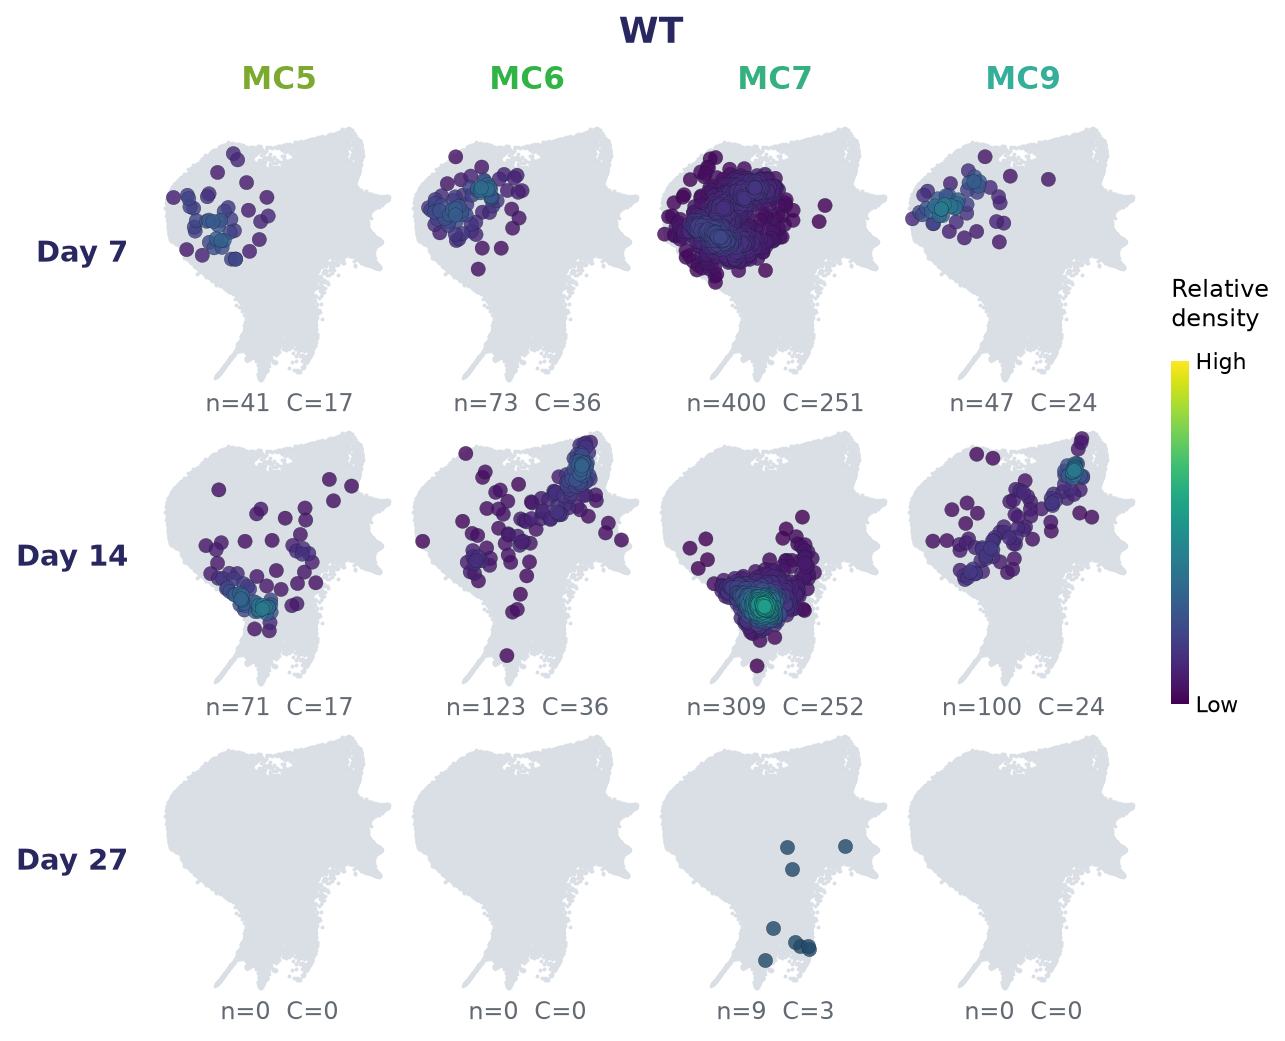

/path/to/ChronoClone/analysis_workspace/singh/singh_figure2b_grid_layout_20260911/panels/atlas_wt_block_02.svg


In [9]:

# One authorized faceted figure: all calculations and full construction visible.
stem='atlas_wt_block_02';metaclones=[5, 6, 7, 9];arms=['WT'];days=['D7', 'D14', 'D27'];column_dimension='mc'
columns=metaclones if column_dimension=='mc' else arms
nc=len(columns);nr=len(days)
previous_figures=set(plt.get_fignums())
fw=1.05+1.55*nc+0.95;fh=0.8+1.90*nr
fig=plt.figure(figsize=(fw,fh),dpi=160,facecolor='white')
labels=[];axes_records=[]
group_label=arms[0] if column_dimension=='mc' else f'MC{metaclones[0]}'
labels.append(fig.text((1.05+1.55*nc/2)/fw,1-0.12/fh,group_label,
                      ha='center',va='top',fontsize=16,fontweight='bold',
                      color='#29275f' if column_dimension=='mc' else MC_LABEL_COLORS[metaclones[0]]))
for j,column in enumerate(columns):
    label=f'MC{column}' if column_dimension=='mc' else column
    labels.append(fig.text((1.05+1.55*(j+.5))/fw,1-0.43/fh,label,
                 ha='center',va='top',fontsize=14,fontweight='bold',
                 color=MC_LABEL_COLORS[column] if column_dimension=='mc' else '#29275f'))
for i,day in enumerate(days):
    bottom=fh-0.8-1.9*(i+1)+0.26
    labels.append(fig.text(0.88/fw,(bottom+.83)/fh,'Day '+day[1:],ha='right',va='center',
                          fontsize=13,fontweight='bold',color='#29275f'))
    for j,column in enumerate(columns):
        mc=column if column_dimension=='mc' else metaclones[0]
        arm=arms[0] if column_dimension=='mc' else column
        selected=cells.loc[cells.mc.eq(mc)&cells.arm.eq(arm)&cells.day.eq(day)].copy()
        n=len(selected);family_count=selected.clone.nunique()
        eligible=n>=MIN_DENSITY_CELLS and family_count>=MIN_DENSITY_FAMILIES
        locked=scale_table.loc[scale_table.mc.eq(mc)&scale_table.arm.eq(arm)&scale_table.day.eq(day)].iloc[0]
        assert (n,family_count)==(locked.cells,locked.families)
        if eligible:
            histogram,_,_=np.histogram2d(selected.umap1,selected.umap2,bins=(X_EDGES,Y_EDGES))
            density=gaussian_filter(histogram/n,sigma=(BANDWIDTH/DX,BANDWIDTH/DY),mode='constant',truncate=4)/(DX*DY)
            assert np.isclose(density.max(),locked.density_peak,rtol=1e-12)
            assert np.isclose(density.sum()*DX*DY,locked.density_integrated_mass,rtol=1e-12)
            point_density=map_coordinates(density,np.vstack(((selected.umap1-X_CENTERS[0])/DX,(selected.umap2-Y_CENTERS[0])/DY)),order=1,mode='nearest')
            order=np.argsort(point_density,kind='stable')
        else:
            point_density=None;order=np.arange(n)
        ax=fig.add_axes([(1.05+1.55*j)/fw,bottom/fh,1.52/fw,1.66/fh])
        ax.set_xlim(PLOT_XLIM);ax.set_ylim(PLOT_YLIM);ax.set_aspect('equal');ax.set_axis_off()
        fig.canvas.draw()
        width_pt=ax.get_window_extent().width/fig.dpi*72
        ratio=width_pt/REFERENCE_AXES_WIDTH_PT
        area=15*MARKER_AREA_MULTIPLIER*ratio**2;background_area=2.2*ratio**2;edge=.12*ratio
        assert np.isclose(np.sqrt(area)/width_pt,np.sqrt(15*MARKER_AREA_MULTIPLIER)/REFERENCE_AXES_WIDTH_PT,rtol=1e-12)
        ax.scatter(full_umap[:,0],full_umap[:,1],s=background_area,c='#d9dfe4',
                   linewidths=0,alpha=1,rasterized=True,zorder=0)
        if n:
            kwargs={'c':point_density[order],'cmap':'viridis','norm':DENSITY_NORM} if eligible else {'c':SPARSE_COLOR}
            ax.scatter(selected.umap1.to_numpy()[order],selected.umap2.to_numpy()[order],s=area,
                       **kwargs,edgecolors='#111827',linewidths=edge,alpha=.82,rasterized=False,zorder=2,clip_on=False)
        labels.append(fig.text((1.05+1.55*(j+.5))/fw,(bottom-.035)/fh,f'n={n:,}  C={family_count:,}',
                               ha='center',va='top',fontsize=11,color='#626972'))
        snapshot_records.append({'stem':stem,'mc':mc,'arm':arm,'day':day,'cells':n,'families':family_count,
                                 'representation':locked.representation,'marker_ratio':np.sqrt(area)/width_pt,
                                 'density_peak':float(locked.density_peak)})
        axes_records.append(ax)
# Integral common-scale key, not a separate analytical panel.
bar=fig.add_axes([(1.05+1.55*nc+.15)/fw,.32,.11/fw,.33])
cb=fig.colorbar(plt.cm.ScalarMappable(norm=DENSITY_NORM,cmap='viridis'),cax=bar)
cb.set_ticks([0,DENSITY_MAX]);cb.set_ticklabels(['Low','High']);cb.ax.tick_params(labelsize=10,length=0,pad=3)
cb.outline.set_visible(False)
labels.append(fig.text((1.05+1.55*nc+.15)/fw,.675,'Relative\ndensity',fontsize=11,ha='left',va='bottom'))
fig.canvas.draw()
renderer=fig.canvas.get_renderer()
for label in labels:
    box=label.get_window_extent(renderer)
    assert box.x0>=0 and box.y0>=0 and box.x1<=fig.bbox.width and box.y1<=fig.bbox.height,(stem,label.get_text(),box)
assert set(plt.get_fignums())-previous_figures=={fig.number}
svg=OUT/'panels'/f'{stem}.svg';png=svg.with_suffix('.png')
fig.savefig(svg);fig.savefig(png,dpi=240)
display(fig);plt.close(fig)
grid_records.append({'stem':stem,'columns':columns,'days':days,'column_dimension':column_dimension,
                     'width_in':fw,'height_in':fh,'svg_sha256':sha256(svg),'png_sha256':sha256(png)})
print(svg)


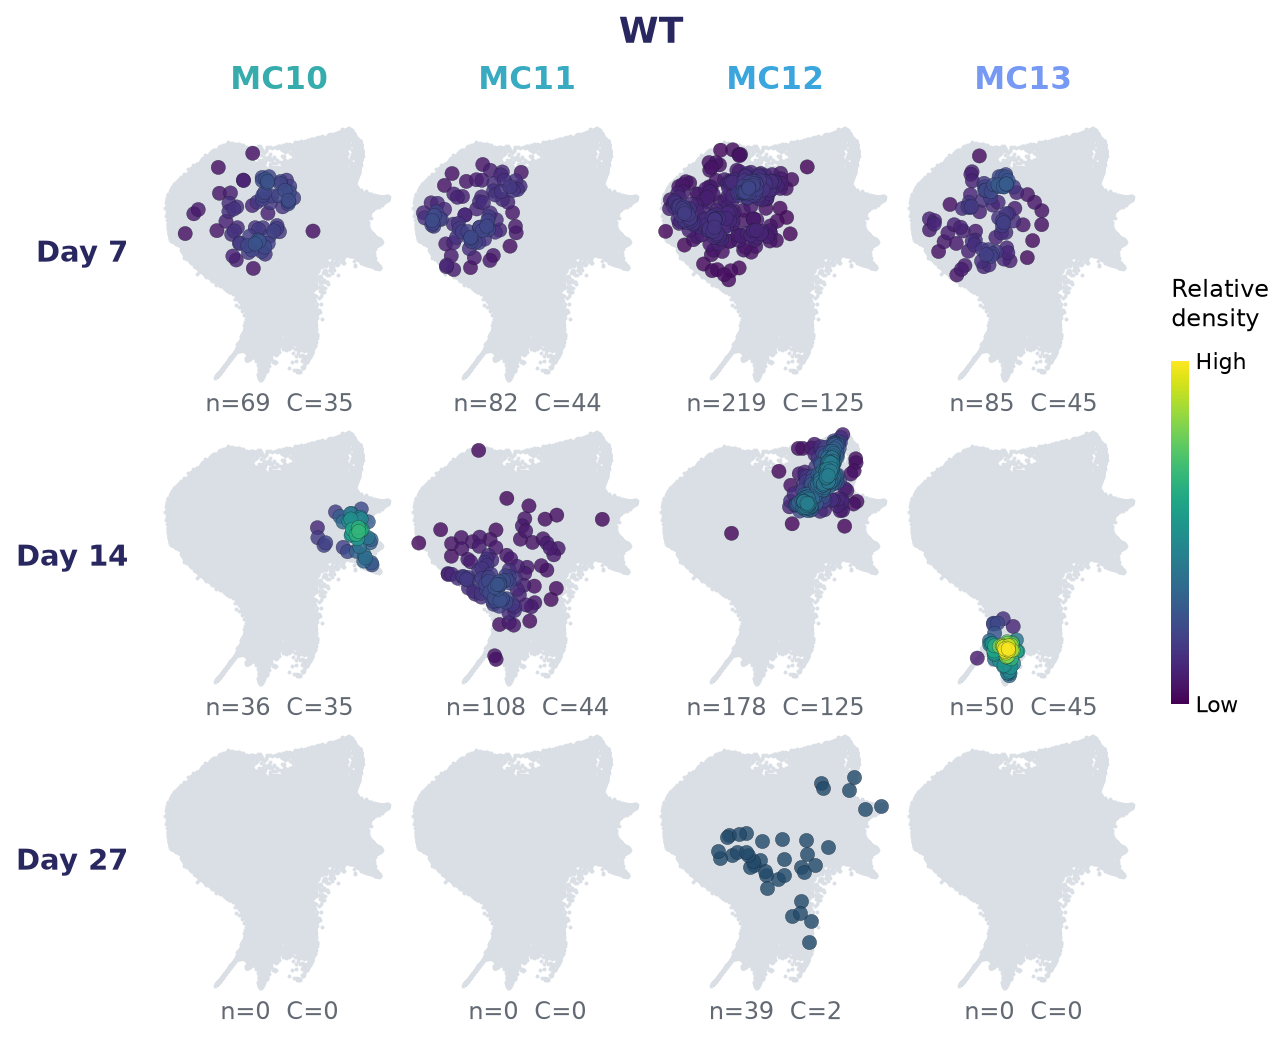

/path/to/ChronoClone/analysis_workspace/singh/singh_figure2b_grid_layout_20260911/panels/atlas_wt_block_03.svg


In [10]:

# One authorized faceted figure: all calculations and full construction visible.
stem='atlas_wt_block_03';metaclones=[10, 11, 12, 13];arms=['WT'];days=['D7', 'D14', 'D27'];column_dimension='mc'
columns=metaclones if column_dimension=='mc' else arms
nc=len(columns);nr=len(days)
previous_figures=set(plt.get_fignums())
fw=1.05+1.55*nc+0.95;fh=0.8+1.90*nr
fig=plt.figure(figsize=(fw,fh),dpi=160,facecolor='white')
labels=[];axes_records=[]
group_label=arms[0] if column_dimension=='mc' else f'MC{metaclones[0]}'
labels.append(fig.text((1.05+1.55*nc/2)/fw,1-0.12/fh,group_label,
                      ha='center',va='top',fontsize=16,fontweight='bold',
                      color='#29275f' if column_dimension=='mc' else MC_LABEL_COLORS[metaclones[0]]))
for j,column in enumerate(columns):
    label=f'MC{column}' if column_dimension=='mc' else column
    labels.append(fig.text((1.05+1.55*(j+.5))/fw,1-0.43/fh,label,
                 ha='center',va='top',fontsize=14,fontweight='bold',
                 color=MC_LABEL_COLORS[column] if column_dimension=='mc' else '#29275f'))
for i,day in enumerate(days):
    bottom=fh-0.8-1.9*(i+1)+0.26
    labels.append(fig.text(0.88/fw,(bottom+.83)/fh,'Day '+day[1:],ha='right',va='center',
                          fontsize=13,fontweight='bold',color='#29275f'))
    for j,column in enumerate(columns):
        mc=column if column_dimension=='mc' else metaclones[0]
        arm=arms[0] if column_dimension=='mc' else column
        selected=cells.loc[cells.mc.eq(mc)&cells.arm.eq(arm)&cells.day.eq(day)].copy()
        n=len(selected);family_count=selected.clone.nunique()
        eligible=n>=MIN_DENSITY_CELLS and family_count>=MIN_DENSITY_FAMILIES
        locked=scale_table.loc[scale_table.mc.eq(mc)&scale_table.arm.eq(arm)&scale_table.day.eq(day)].iloc[0]
        assert (n,family_count)==(locked.cells,locked.families)
        if eligible:
            histogram,_,_=np.histogram2d(selected.umap1,selected.umap2,bins=(X_EDGES,Y_EDGES))
            density=gaussian_filter(histogram/n,sigma=(BANDWIDTH/DX,BANDWIDTH/DY),mode='constant',truncate=4)/(DX*DY)
            assert np.isclose(density.max(),locked.density_peak,rtol=1e-12)
            assert np.isclose(density.sum()*DX*DY,locked.density_integrated_mass,rtol=1e-12)
            point_density=map_coordinates(density,np.vstack(((selected.umap1-X_CENTERS[0])/DX,(selected.umap2-Y_CENTERS[0])/DY)),order=1,mode='nearest')
            order=np.argsort(point_density,kind='stable')
        else:
            point_density=None;order=np.arange(n)
        ax=fig.add_axes([(1.05+1.55*j)/fw,bottom/fh,1.52/fw,1.66/fh])
        ax.set_xlim(PLOT_XLIM);ax.set_ylim(PLOT_YLIM);ax.set_aspect('equal');ax.set_axis_off()
        fig.canvas.draw()
        width_pt=ax.get_window_extent().width/fig.dpi*72
        ratio=width_pt/REFERENCE_AXES_WIDTH_PT
        area=15*MARKER_AREA_MULTIPLIER*ratio**2;background_area=2.2*ratio**2;edge=.12*ratio
        assert np.isclose(np.sqrt(area)/width_pt,np.sqrt(15*MARKER_AREA_MULTIPLIER)/REFERENCE_AXES_WIDTH_PT,rtol=1e-12)
        ax.scatter(full_umap[:,0],full_umap[:,1],s=background_area,c='#d9dfe4',
                   linewidths=0,alpha=1,rasterized=True,zorder=0)
        if n:
            kwargs={'c':point_density[order],'cmap':'viridis','norm':DENSITY_NORM} if eligible else {'c':SPARSE_COLOR}
            ax.scatter(selected.umap1.to_numpy()[order],selected.umap2.to_numpy()[order],s=area,
                       **kwargs,edgecolors='#111827',linewidths=edge,alpha=.82,rasterized=False,zorder=2,clip_on=False)
        labels.append(fig.text((1.05+1.55*(j+.5))/fw,(bottom-.035)/fh,f'n={n:,}  C={family_count:,}',
                               ha='center',va='top',fontsize=11,color='#626972'))
        snapshot_records.append({'stem':stem,'mc':mc,'arm':arm,'day':day,'cells':n,'families':family_count,
                                 'representation':locked.representation,'marker_ratio':np.sqrt(area)/width_pt,
                                 'density_peak':float(locked.density_peak)})
        axes_records.append(ax)
# Integral common-scale key, not a separate analytical panel.
bar=fig.add_axes([(1.05+1.55*nc+.15)/fw,.32,.11/fw,.33])
cb=fig.colorbar(plt.cm.ScalarMappable(norm=DENSITY_NORM,cmap='viridis'),cax=bar)
cb.set_ticks([0,DENSITY_MAX]);cb.set_ticklabels(['Low','High']);cb.ax.tick_params(labelsize=10,length=0,pad=3)
cb.outline.set_visible(False)
labels.append(fig.text((1.05+1.55*nc+.15)/fw,.675,'Relative\ndensity',fontsize=11,ha='left',va='bottom'))
fig.canvas.draw()
renderer=fig.canvas.get_renderer()
for label in labels:
    box=label.get_window_extent(renderer)
    assert box.x0>=0 and box.y0>=0 and box.x1<=fig.bbox.width and box.y1<=fig.bbox.height,(stem,label.get_text(),box)
assert set(plt.get_fignums())-previous_figures=={fig.number}
svg=OUT/'panels'/f'{stem}.svg';png=svg.with_suffix('.png')
fig.savefig(svg);fig.savefig(png,dpi=240)
display(fig);plt.close(fig)
grid_records.append({'stem':stem,'columns':columns,'days':days,'column_dimension':column_dimension,
                     'width_in':fw,'height_in':fh,'svg_sha256':sha256(svg),'png_sha256':sha256(png)})
print(svg)


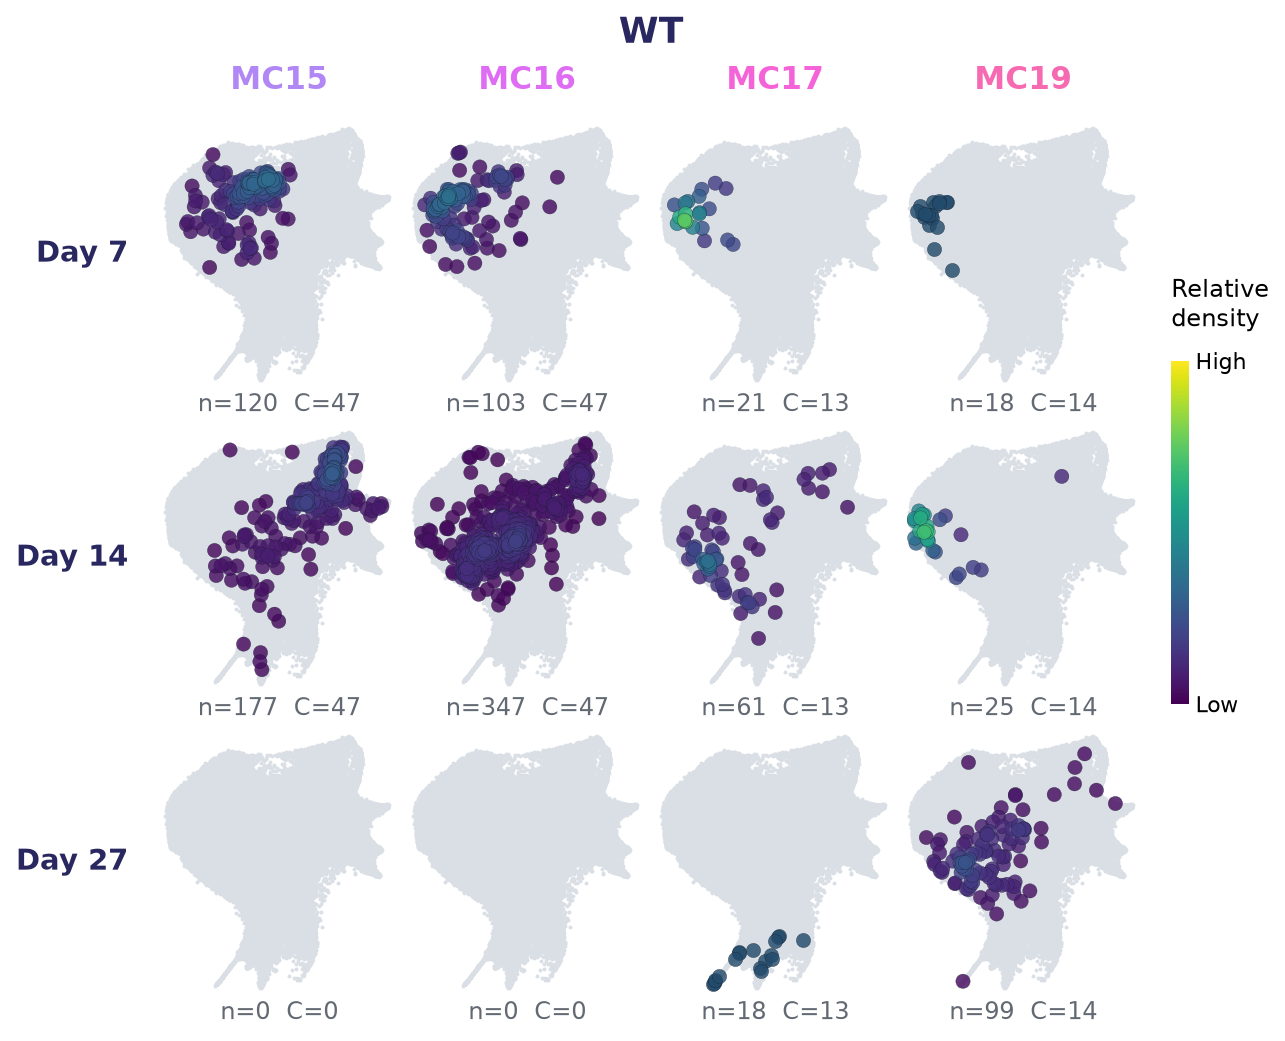

/path/to/ChronoClone/analysis_workspace/singh/singh_figure2b_grid_layout_20260911/panels/atlas_wt_block_04.svg


In [11]:

# One authorized faceted figure: all calculations and full construction visible.
stem='atlas_wt_block_04';metaclones=[15, 16, 17, 19];arms=['WT'];days=['D7', 'D14', 'D27'];column_dimension='mc'
columns=metaclones if column_dimension=='mc' else arms
nc=len(columns);nr=len(days)
previous_figures=set(plt.get_fignums())
fw=1.05+1.55*nc+0.95;fh=0.8+1.90*nr
fig=plt.figure(figsize=(fw,fh),dpi=160,facecolor='white')
labels=[];axes_records=[]
group_label=arms[0] if column_dimension=='mc' else f'MC{metaclones[0]}'
labels.append(fig.text((1.05+1.55*nc/2)/fw,1-0.12/fh,group_label,
                      ha='center',va='top',fontsize=16,fontweight='bold',
                      color='#29275f' if column_dimension=='mc' else MC_LABEL_COLORS[metaclones[0]]))
for j,column in enumerate(columns):
    label=f'MC{column}' if column_dimension=='mc' else column
    labels.append(fig.text((1.05+1.55*(j+.5))/fw,1-0.43/fh,label,
                 ha='center',va='top',fontsize=14,fontweight='bold',
                 color=MC_LABEL_COLORS[column] if column_dimension=='mc' else '#29275f'))
for i,day in enumerate(days):
    bottom=fh-0.8-1.9*(i+1)+0.26
    labels.append(fig.text(0.88/fw,(bottom+.83)/fh,'Day '+day[1:],ha='right',va='center',
                          fontsize=13,fontweight='bold',color='#29275f'))
    for j,column in enumerate(columns):
        mc=column if column_dimension=='mc' else metaclones[0]
        arm=arms[0] if column_dimension=='mc' else column
        selected=cells.loc[cells.mc.eq(mc)&cells.arm.eq(arm)&cells.day.eq(day)].copy()
        n=len(selected);family_count=selected.clone.nunique()
        eligible=n>=MIN_DENSITY_CELLS and family_count>=MIN_DENSITY_FAMILIES
        locked=scale_table.loc[scale_table.mc.eq(mc)&scale_table.arm.eq(arm)&scale_table.day.eq(day)].iloc[0]
        assert (n,family_count)==(locked.cells,locked.families)
        if eligible:
            histogram,_,_=np.histogram2d(selected.umap1,selected.umap2,bins=(X_EDGES,Y_EDGES))
            density=gaussian_filter(histogram/n,sigma=(BANDWIDTH/DX,BANDWIDTH/DY),mode='constant',truncate=4)/(DX*DY)
            assert np.isclose(density.max(),locked.density_peak,rtol=1e-12)
            assert np.isclose(density.sum()*DX*DY,locked.density_integrated_mass,rtol=1e-12)
            point_density=map_coordinates(density,np.vstack(((selected.umap1-X_CENTERS[0])/DX,(selected.umap2-Y_CENTERS[0])/DY)),order=1,mode='nearest')
            order=np.argsort(point_density,kind='stable')
        else:
            point_density=None;order=np.arange(n)
        ax=fig.add_axes([(1.05+1.55*j)/fw,bottom/fh,1.52/fw,1.66/fh])
        ax.set_xlim(PLOT_XLIM);ax.set_ylim(PLOT_YLIM);ax.set_aspect('equal');ax.set_axis_off()
        fig.canvas.draw()
        width_pt=ax.get_window_extent().width/fig.dpi*72
        ratio=width_pt/REFERENCE_AXES_WIDTH_PT
        area=15*MARKER_AREA_MULTIPLIER*ratio**2;background_area=2.2*ratio**2;edge=.12*ratio
        assert np.isclose(np.sqrt(area)/width_pt,np.sqrt(15*MARKER_AREA_MULTIPLIER)/REFERENCE_AXES_WIDTH_PT,rtol=1e-12)
        ax.scatter(full_umap[:,0],full_umap[:,1],s=background_area,c='#d9dfe4',
                   linewidths=0,alpha=1,rasterized=True,zorder=0)
        if n:
            kwargs={'c':point_density[order],'cmap':'viridis','norm':DENSITY_NORM} if eligible else {'c':SPARSE_COLOR}
            ax.scatter(selected.umap1.to_numpy()[order],selected.umap2.to_numpy()[order],s=area,
                       **kwargs,edgecolors='#111827',linewidths=edge,alpha=.82,rasterized=False,zorder=2,clip_on=False)
        labels.append(fig.text((1.05+1.55*(j+.5))/fw,(bottom-.035)/fh,f'n={n:,}  C={family_count:,}',
                               ha='center',va='top',fontsize=11,color='#626972'))
        snapshot_records.append({'stem':stem,'mc':mc,'arm':arm,'day':day,'cells':n,'families':family_count,
                                 'representation':locked.representation,'marker_ratio':np.sqrt(area)/width_pt,
                                 'density_peak':float(locked.density_peak)})
        axes_records.append(ax)
# Integral common-scale key, not a separate analytical panel.
bar=fig.add_axes([(1.05+1.55*nc+.15)/fw,.32,.11/fw,.33])
cb=fig.colorbar(plt.cm.ScalarMappable(norm=DENSITY_NORM,cmap='viridis'),cax=bar)
cb.set_ticks([0,DENSITY_MAX]);cb.set_ticklabels(['Low','High']);cb.ax.tick_params(labelsize=10,length=0,pad=3)
cb.outline.set_visible(False)
labels.append(fig.text((1.05+1.55*nc+.15)/fw,.675,'Relative\ndensity',fontsize=11,ha='left',va='bottom'))
fig.canvas.draw()
renderer=fig.canvas.get_renderer()
for label in labels:
    box=label.get_window_extent(renderer)
    assert box.x0>=0 and box.y0>=0 and box.x1<=fig.bbox.width and box.y1<=fig.bbox.height,(stem,label.get_text(),box)
assert set(plt.get_fignums())-previous_figures=={fig.number}
svg=OUT/'panels'/f'{stem}.svg';png=svg.with_suffix('.png')
fig.savefig(svg);fig.savefig(png,dpi=240)
display(fig);plt.close(fig)
grid_records.append({'stem':stem,'columns':columns,'days':days,'column_dimension':column_dimension,
                     'width_in':fw,'height_in':fh,'svg_sha256':sha256(svg),'png_sha256':sha256(png)})
print(svg)


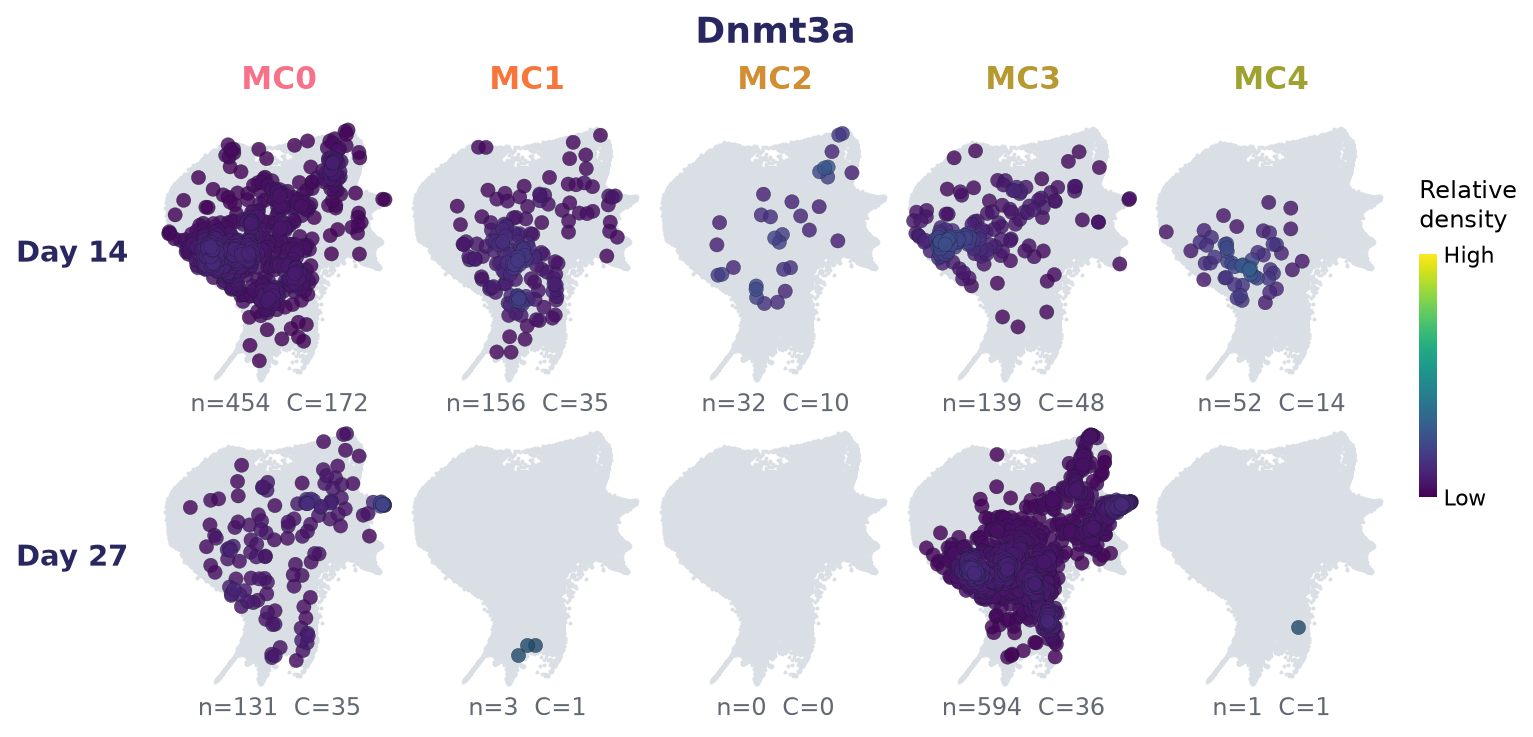

/path/to/ChronoClone/analysis_workspace/singh/singh_figure2b_grid_layout_20260911/panels/atlas_dnmt3a_block_01.svg


In [12]:

# One authorized faceted figure: all calculations and full construction visible.
stem='atlas_dnmt3a_block_01';metaclones=[0, 1, 2, 3, 4];arms=['Dnmt3a'];days=['D14', 'D27'];column_dimension='mc'
columns=metaclones if column_dimension=='mc' else arms
nc=len(columns);nr=len(days)
previous_figures=set(plt.get_fignums())
fw=1.05+1.55*nc+0.95;fh=0.8+1.90*nr
fig=plt.figure(figsize=(fw,fh),dpi=160,facecolor='white')
labels=[];axes_records=[]
group_label=arms[0] if column_dimension=='mc' else f'MC{metaclones[0]}'
labels.append(fig.text((1.05+1.55*nc/2)/fw,1-0.12/fh,group_label,
                      ha='center',va='top',fontsize=16,fontweight='bold',
                      color='#29275f' if column_dimension=='mc' else MC_LABEL_COLORS[metaclones[0]]))
for j,column in enumerate(columns):
    label=f'MC{column}' if column_dimension=='mc' else column
    labels.append(fig.text((1.05+1.55*(j+.5))/fw,1-0.43/fh,label,
                 ha='center',va='top',fontsize=14,fontweight='bold',
                 color=MC_LABEL_COLORS[column] if column_dimension=='mc' else '#29275f'))
for i,day in enumerate(days):
    bottom=fh-0.8-1.9*(i+1)+0.26
    labels.append(fig.text(0.88/fw,(bottom+.83)/fh,'Day '+day[1:],ha='right',va='center',
                          fontsize=13,fontweight='bold',color='#29275f'))
    for j,column in enumerate(columns):
        mc=column if column_dimension=='mc' else metaclones[0]
        arm=arms[0] if column_dimension=='mc' else column
        selected=cells.loc[cells.mc.eq(mc)&cells.arm.eq(arm)&cells.day.eq(day)].copy()
        n=len(selected);family_count=selected.clone.nunique()
        eligible=n>=MIN_DENSITY_CELLS and family_count>=MIN_DENSITY_FAMILIES
        locked=scale_table.loc[scale_table.mc.eq(mc)&scale_table.arm.eq(arm)&scale_table.day.eq(day)].iloc[0]
        assert (n,family_count)==(locked.cells,locked.families)
        if eligible:
            histogram,_,_=np.histogram2d(selected.umap1,selected.umap2,bins=(X_EDGES,Y_EDGES))
            density=gaussian_filter(histogram/n,sigma=(BANDWIDTH/DX,BANDWIDTH/DY),mode='constant',truncate=4)/(DX*DY)
            assert np.isclose(density.max(),locked.density_peak,rtol=1e-12)
            assert np.isclose(density.sum()*DX*DY,locked.density_integrated_mass,rtol=1e-12)
            point_density=map_coordinates(density,np.vstack(((selected.umap1-X_CENTERS[0])/DX,(selected.umap2-Y_CENTERS[0])/DY)),order=1,mode='nearest')
            order=np.argsort(point_density,kind='stable')
        else:
            point_density=None;order=np.arange(n)
        ax=fig.add_axes([(1.05+1.55*j)/fw,bottom/fh,1.52/fw,1.66/fh])
        ax.set_xlim(PLOT_XLIM);ax.set_ylim(PLOT_YLIM);ax.set_aspect('equal');ax.set_axis_off()
        fig.canvas.draw()
        width_pt=ax.get_window_extent().width/fig.dpi*72
        ratio=width_pt/REFERENCE_AXES_WIDTH_PT
        area=15*MARKER_AREA_MULTIPLIER*ratio**2;background_area=2.2*ratio**2;edge=.12*ratio
        assert np.isclose(np.sqrt(area)/width_pt,np.sqrt(15*MARKER_AREA_MULTIPLIER)/REFERENCE_AXES_WIDTH_PT,rtol=1e-12)
        ax.scatter(full_umap[:,0],full_umap[:,1],s=background_area,c='#d9dfe4',
                   linewidths=0,alpha=1,rasterized=True,zorder=0)
        if n:
            kwargs={'c':point_density[order],'cmap':'viridis','norm':DENSITY_NORM} if eligible else {'c':SPARSE_COLOR}
            ax.scatter(selected.umap1.to_numpy()[order],selected.umap2.to_numpy()[order],s=area,
                       **kwargs,edgecolors='#111827',linewidths=edge,alpha=.82,rasterized=False,zorder=2,clip_on=False)
        labels.append(fig.text((1.05+1.55*(j+.5))/fw,(bottom-.035)/fh,f'n={n:,}  C={family_count:,}',
                               ha='center',va='top',fontsize=11,color='#626972'))
        snapshot_records.append({'stem':stem,'mc':mc,'arm':arm,'day':day,'cells':n,'families':family_count,
                                 'representation':locked.representation,'marker_ratio':np.sqrt(area)/width_pt,
                                 'density_peak':float(locked.density_peak)})
        axes_records.append(ax)
# Integral common-scale key, not a separate analytical panel.
bar=fig.add_axes([(1.05+1.55*nc+.15)/fw,.32,.11/fw,.33])
cb=fig.colorbar(plt.cm.ScalarMappable(norm=DENSITY_NORM,cmap='viridis'),cax=bar)
cb.set_ticks([0,DENSITY_MAX]);cb.set_ticklabels(['Low','High']);cb.ax.tick_params(labelsize=10,length=0,pad=3)
cb.outline.set_visible(False)
labels.append(fig.text((1.05+1.55*nc+.15)/fw,.675,'Relative\ndensity',fontsize=11,ha='left',va='bottom'))
fig.canvas.draw()
renderer=fig.canvas.get_renderer()
for label in labels:
    box=label.get_window_extent(renderer)
    assert box.x0>=0 and box.y0>=0 and box.x1<=fig.bbox.width and box.y1<=fig.bbox.height,(stem,label.get_text(),box)
assert set(plt.get_fignums())-previous_figures=={fig.number}
svg=OUT/'panels'/f'{stem}.svg';png=svg.with_suffix('.png')
fig.savefig(svg);fig.savefig(png,dpi=240)
display(fig);plt.close(fig)
grid_records.append({'stem':stem,'columns':columns,'days':days,'column_dimension':column_dimension,
                     'width_in':fw,'height_in':fh,'svg_sha256':sha256(svg),'png_sha256':sha256(png)})
print(svg)


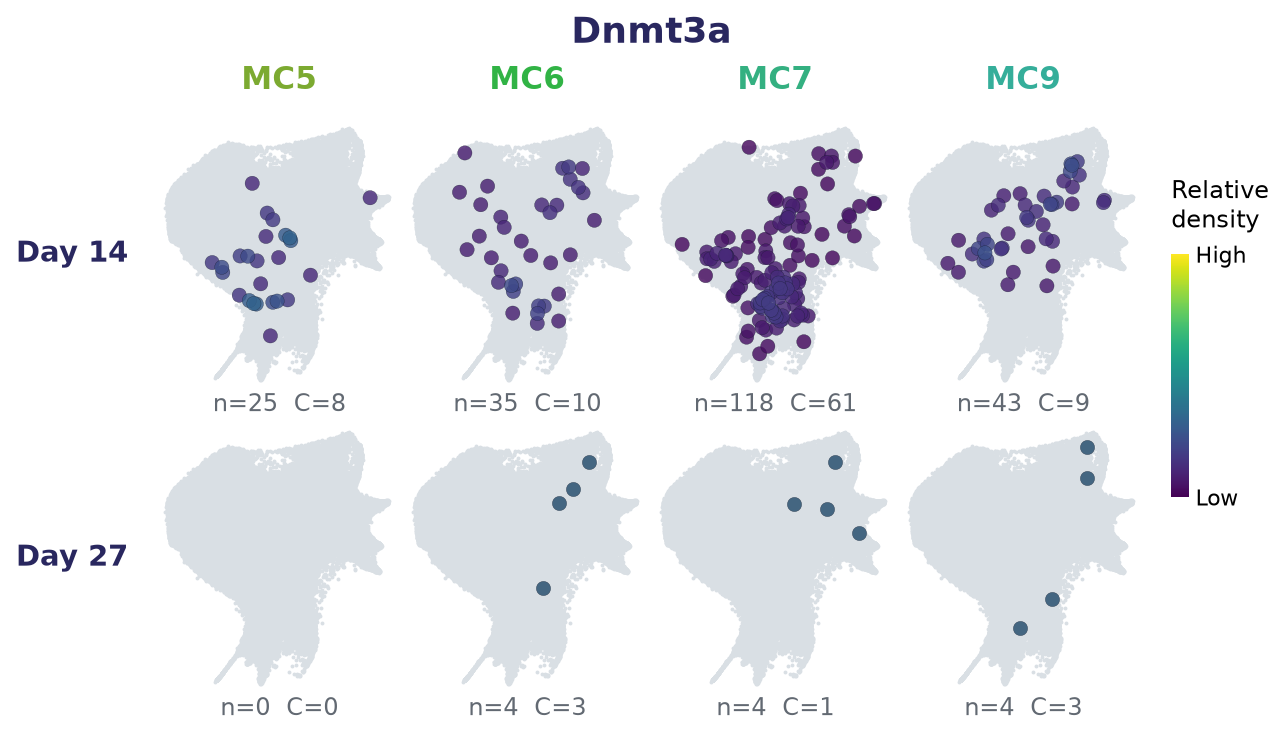

/path/to/ChronoClone/analysis_workspace/singh/singh_figure2b_grid_layout_20260911/panels/atlas_dnmt3a_block_02.svg


In [13]:

# One authorized faceted figure: all calculations and full construction visible.
stem='atlas_dnmt3a_block_02';metaclones=[5, 6, 7, 9];arms=['Dnmt3a'];days=['D14', 'D27'];column_dimension='mc'
columns=metaclones if column_dimension=='mc' else arms
nc=len(columns);nr=len(days)
previous_figures=set(plt.get_fignums())
fw=1.05+1.55*nc+0.95;fh=0.8+1.90*nr
fig=plt.figure(figsize=(fw,fh),dpi=160,facecolor='white')
labels=[];axes_records=[]
group_label=arms[0] if column_dimension=='mc' else f'MC{metaclones[0]}'
labels.append(fig.text((1.05+1.55*nc/2)/fw,1-0.12/fh,group_label,
                      ha='center',va='top',fontsize=16,fontweight='bold',
                      color='#29275f' if column_dimension=='mc' else MC_LABEL_COLORS[metaclones[0]]))
for j,column in enumerate(columns):
    label=f'MC{column}' if column_dimension=='mc' else column
    labels.append(fig.text((1.05+1.55*(j+.5))/fw,1-0.43/fh,label,
                 ha='center',va='top',fontsize=14,fontweight='bold',
                 color=MC_LABEL_COLORS[column] if column_dimension=='mc' else '#29275f'))
for i,day in enumerate(days):
    bottom=fh-0.8-1.9*(i+1)+0.26
    labels.append(fig.text(0.88/fw,(bottom+.83)/fh,'Day '+day[1:],ha='right',va='center',
                          fontsize=13,fontweight='bold',color='#29275f'))
    for j,column in enumerate(columns):
        mc=column if column_dimension=='mc' else metaclones[0]
        arm=arms[0] if column_dimension=='mc' else column
        selected=cells.loc[cells.mc.eq(mc)&cells.arm.eq(arm)&cells.day.eq(day)].copy()
        n=len(selected);family_count=selected.clone.nunique()
        eligible=n>=MIN_DENSITY_CELLS and family_count>=MIN_DENSITY_FAMILIES
        locked=scale_table.loc[scale_table.mc.eq(mc)&scale_table.arm.eq(arm)&scale_table.day.eq(day)].iloc[0]
        assert (n,family_count)==(locked.cells,locked.families)
        if eligible:
            histogram,_,_=np.histogram2d(selected.umap1,selected.umap2,bins=(X_EDGES,Y_EDGES))
            density=gaussian_filter(histogram/n,sigma=(BANDWIDTH/DX,BANDWIDTH/DY),mode='constant',truncate=4)/(DX*DY)
            assert np.isclose(density.max(),locked.density_peak,rtol=1e-12)
            assert np.isclose(density.sum()*DX*DY,locked.density_integrated_mass,rtol=1e-12)
            point_density=map_coordinates(density,np.vstack(((selected.umap1-X_CENTERS[0])/DX,(selected.umap2-Y_CENTERS[0])/DY)),order=1,mode='nearest')
            order=np.argsort(point_density,kind='stable')
        else:
            point_density=None;order=np.arange(n)
        ax=fig.add_axes([(1.05+1.55*j)/fw,bottom/fh,1.52/fw,1.66/fh])
        ax.set_xlim(PLOT_XLIM);ax.set_ylim(PLOT_YLIM);ax.set_aspect('equal');ax.set_axis_off()
        fig.canvas.draw()
        width_pt=ax.get_window_extent().width/fig.dpi*72
        ratio=width_pt/REFERENCE_AXES_WIDTH_PT
        area=15*MARKER_AREA_MULTIPLIER*ratio**2;background_area=2.2*ratio**2;edge=.12*ratio
        assert np.isclose(np.sqrt(area)/width_pt,np.sqrt(15*MARKER_AREA_MULTIPLIER)/REFERENCE_AXES_WIDTH_PT,rtol=1e-12)
        ax.scatter(full_umap[:,0],full_umap[:,1],s=background_area,c='#d9dfe4',
                   linewidths=0,alpha=1,rasterized=True,zorder=0)
        if n:
            kwargs={'c':point_density[order],'cmap':'viridis','norm':DENSITY_NORM} if eligible else {'c':SPARSE_COLOR}
            ax.scatter(selected.umap1.to_numpy()[order],selected.umap2.to_numpy()[order],s=area,
                       **kwargs,edgecolors='#111827',linewidths=edge,alpha=.82,rasterized=False,zorder=2,clip_on=False)
        labels.append(fig.text((1.05+1.55*(j+.5))/fw,(bottom-.035)/fh,f'n={n:,}  C={family_count:,}',
                               ha='center',va='top',fontsize=11,color='#626972'))
        snapshot_records.append({'stem':stem,'mc':mc,'arm':arm,'day':day,'cells':n,'families':family_count,
                                 'representation':locked.representation,'marker_ratio':np.sqrt(area)/width_pt,
                                 'density_peak':float(locked.density_peak)})
        axes_records.append(ax)
# Integral common-scale key, not a separate analytical panel.
bar=fig.add_axes([(1.05+1.55*nc+.15)/fw,.32,.11/fw,.33])
cb=fig.colorbar(plt.cm.ScalarMappable(norm=DENSITY_NORM,cmap='viridis'),cax=bar)
cb.set_ticks([0,DENSITY_MAX]);cb.set_ticklabels(['Low','High']);cb.ax.tick_params(labelsize=10,length=0,pad=3)
cb.outline.set_visible(False)
labels.append(fig.text((1.05+1.55*nc+.15)/fw,.675,'Relative\ndensity',fontsize=11,ha='left',va='bottom'))
fig.canvas.draw()
renderer=fig.canvas.get_renderer()
for label in labels:
    box=label.get_window_extent(renderer)
    assert box.x0>=0 and box.y0>=0 and box.x1<=fig.bbox.width and box.y1<=fig.bbox.height,(stem,label.get_text(),box)
assert set(plt.get_fignums())-previous_figures=={fig.number}
svg=OUT/'panels'/f'{stem}.svg';png=svg.with_suffix('.png')
fig.savefig(svg);fig.savefig(png,dpi=240)
display(fig);plt.close(fig)
grid_records.append({'stem':stem,'columns':columns,'days':days,'column_dimension':column_dimension,
                     'width_in':fw,'height_in':fh,'svg_sha256':sha256(svg),'png_sha256':sha256(png)})
print(svg)


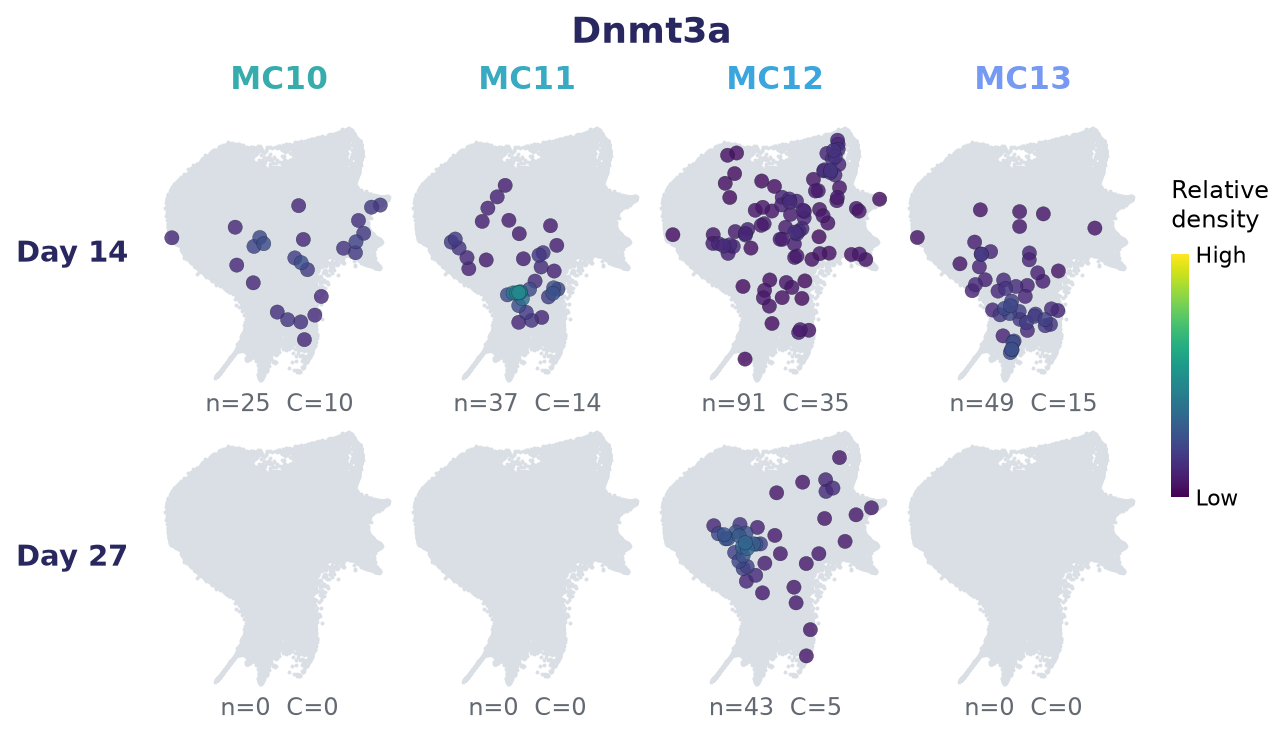

/path/to/ChronoClone/analysis_workspace/singh/singh_figure2b_grid_layout_20260911/panels/atlas_dnmt3a_block_03.svg


In [14]:

# One authorized faceted figure: all calculations and full construction visible.
stem='atlas_dnmt3a_block_03';metaclones=[10, 11, 12, 13];arms=['Dnmt3a'];days=['D14', 'D27'];column_dimension='mc'
columns=metaclones if column_dimension=='mc' else arms
nc=len(columns);nr=len(days)
previous_figures=set(plt.get_fignums())
fw=1.05+1.55*nc+0.95;fh=0.8+1.90*nr
fig=plt.figure(figsize=(fw,fh),dpi=160,facecolor='white')
labels=[];axes_records=[]
group_label=arms[0] if column_dimension=='mc' else f'MC{metaclones[0]}'
labels.append(fig.text((1.05+1.55*nc/2)/fw,1-0.12/fh,group_label,
                      ha='center',va='top',fontsize=16,fontweight='bold',
                      color='#29275f' if column_dimension=='mc' else MC_LABEL_COLORS[metaclones[0]]))
for j,column in enumerate(columns):
    label=f'MC{column}' if column_dimension=='mc' else column
    labels.append(fig.text((1.05+1.55*(j+.5))/fw,1-0.43/fh,label,
                 ha='center',va='top',fontsize=14,fontweight='bold',
                 color=MC_LABEL_COLORS[column] if column_dimension=='mc' else '#29275f'))
for i,day in enumerate(days):
    bottom=fh-0.8-1.9*(i+1)+0.26
    labels.append(fig.text(0.88/fw,(bottom+.83)/fh,'Day '+day[1:],ha='right',va='center',
                          fontsize=13,fontweight='bold',color='#29275f'))
    for j,column in enumerate(columns):
        mc=column if column_dimension=='mc' else metaclones[0]
        arm=arms[0] if column_dimension=='mc' else column
        selected=cells.loc[cells.mc.eq(mc)&cells.arm.eq(arm)&cells.day.eq(day)].copy()
        n=len(selected);family_count=selected.clone.nunique()
        eligible=n>=MIN_DENSITY_CELLS and family_count>=MIN_DENSITY_FAMILIES
        locked=scale_table.loc[scale_table.mc.eq(mc)&scale_table.arm.eq(arm)&scale_table.day.eq(day)].iloc[0]
        assert (n,family_count)==(locked.cells,locked.families)
        if eligible:
            histogram,_,_=np.histogram2d(selected.umap1,selected.umap2,bins=(X_EDGES,Y_EDGES))
            density=gaussian_filter(histogram/n,sigma=(BANDWIDTH/DX,BANDWIDTH/DY),mode='constant',truncate=4)/(DX*DY)
            assert np.isclose(density.max(),locked.density_peak,rtol=1e-12)
            assert np.isclose(density.sum()*DX*DY,locked.density_integrated_mass,rtol=1e-12)
            point_density=map_coordinates(density,np.vstack(((selected.umap1-X_CENTERS[0])/DX,(selected.umap2-Y_CENTERS[0])/DY)),order=1,mode='nearest')
            order=np.argsort(point_density,kind='stable')
        else:
            point_density=None;order=np.arange(n)
        ax=fig.add_axes([(1.05+1.55*j)/fw,bottom/fh,1.52/fw,1.66/fh])
        ax.set_xlim(PLOT_XLIM);ax.set_ylim(PLOT_YLIM);ax.set_aspect('equal');ax.set_axis_off()
        fig.canvas.draw()
        width_pt=ax.get_window_extent().width/fig.dpi*72
        ratio=width_pt/REFERENCE_AXES_WIDTH_PT
        area=15*MARKER_AREA_MULTIPLIER*ratio**2;background_area=2.2*ratio**2;edge=.12*ratio
        assert np.isclose(np.sqrt(area)/width_pt,np.sqrt(15*MARKER_AREA_MULTIPLIER)/REFERENCE_AXES_WIDTH_PT,rtol=1e-12)
        ax.scatter(full_umap[:,0],full_umap[:,1],s=background_area,c='#d9dfe4',
                   linewidths=0,alpha=1,rasterized=True,zorder=0)
        if n:
            kwargs={'c':point_density[order],'cmap':'viridis','norm':DENSITY_NORM} if eligible else {'c':SPARSE_COLOR}
            ax.scatter(selected.umap1.to_numpy()[order],selected.umap2.to_numpy()[order],s=area,
                       **kwargs,edgecolors='#111827',linewidths=edge,alpha=.82,rasterized=False,zorder=2,clip_on=False)
        labels.append(fig.text((1.05+1.55*(j+.5))/fw,(bottom-.035)/fh,f'n={n:,}  C={family_count:,}',
                               ha='center',va='top',fontsize=11,color='#626972'))
        snapshot_records.append({'stem':stem,'mc':mc,'arm':arm,'day':day,'cells':n,'families':family_count,
                                 'representation':locked.representation,'marker_ratio':np.sqrt(area)/width_pt,
                                 'density_peak':float(locked.density_peak)})
        axes_records.append(ax)
# Integral common-scale key, not a separate analytical panel.
bar=fig.add_axes([(1.05+1.55*nc+.15)/fw,.32,.11/fw,.33])
cb=fig.colorbar(plt.cm.ScalarMappable(norm=DENSITY_NORM,cmap='viridis'),cax=bar)
cb.set_ticks([0,DENSITY_MAX]);cb.set_ticklabels(['Low','High']);cb.ax.tick_params(labelsize=10,length=0,pad=3)
cb.outline.set_visible(False)
labels.append(fig.text((1.05+1.55*nc+.15)/fw,.675,'Relative\ndensity',fontsize=11,ha='left',va='bottom'))
fig.canvas.draw()
renderer=fig.canvas.get_renderer()
for label in labels:
    box=label.get_window_extent(renderer)
    assert box.x0>=0 and box.y0>=0 and box.x1<=fig.bbox.width and box.y1<=fig.bbox.height,(stem,label.get_text(),box)
assert set(plt.get_fignums())-previous_figures=={fig.number}
svg=OUT/'panels'/f'{stem}.svg';png=svg.with_suffix('.png')
fig.savefig(svg);fig.savefig(png,dpi=240)
display(fig);plt.close(fig)
grid_records.append({'stem':stem,'columns':columns,'days':days,'column_dimension':column_dimension,
                     'width_in':fw,'height_in':fh,'svg_sha256':sha256(svg),'png_sha256':sha256(png)})
print(svg)


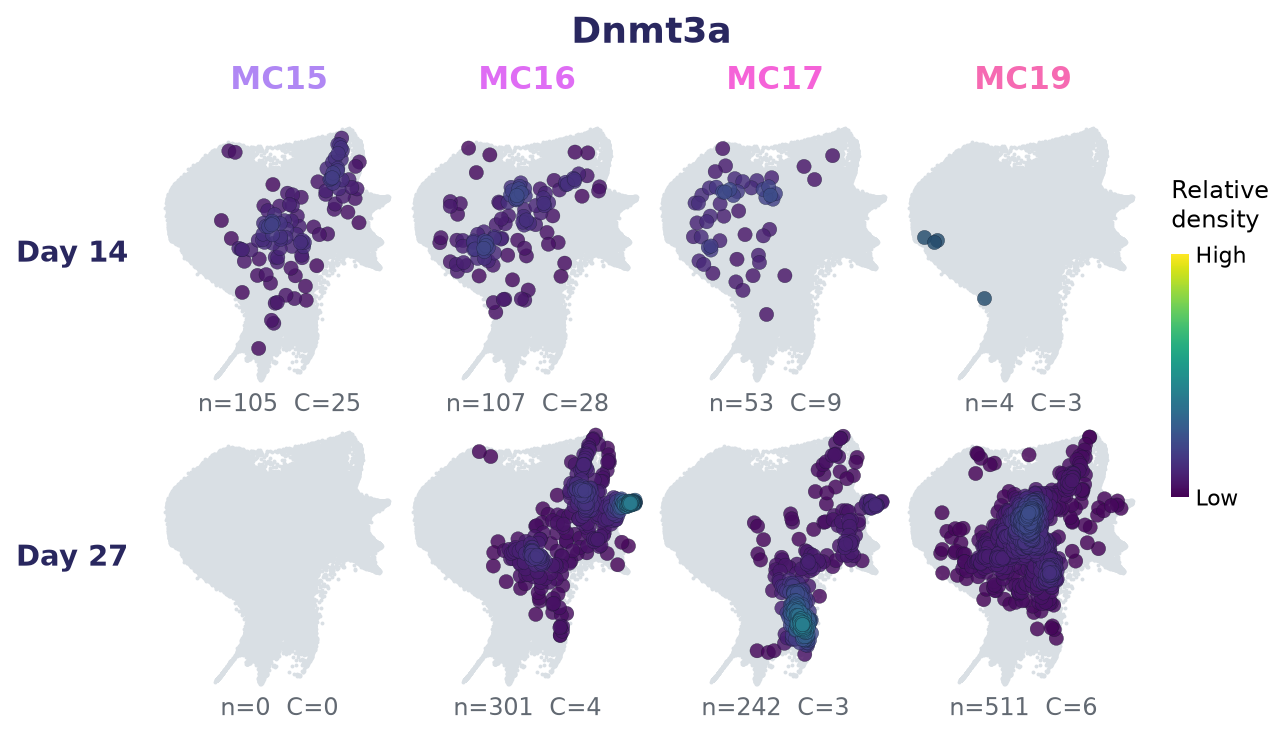

/path/to/ChronoClone/analysis_workspace/singh/singh_figure2b_grid_layout_20260911/panels/atlas_dnmt3a_block_04.svg


In [15]:

# One authorized faceted figure: all calculations and full construction visible.
stem='atlas_dnmt3a_block_04';metaclones=[15, 16, 17, 19];arms=['Dnmt3a'];days=['D14', 'D27'];column_dimension='mc'
columns=metaclones if column_dimension=='mc' else arms
nc=len(columns);nr=len(days)
previous_figures=set(plt.get_fignums())
fw=1.05+1.55*nc+0.95;fh=0.8+1.90*nr
fig=plt.figure(figsize=(fw,fh),dpi=160,facecolor='white')
labels=[];axes_records=[]
group_label=arms[0] if column_dimension=='mc' else f'MC{metaclones[0]}'
labels.append(fig.text((1.05+1.55*nc/2)/fw,1-0.12/fh,group_label,
                      ha='center',va='top',fontsize=16,fontweight='bold',
                      color='#29275f' if column_dimension=='mc' else MC_LABEL_COLORS[metaclones[0]]))
for j,column in enumerate(columns):
    label=f'MC{column}' if column_dimension=='mc' else column
    labels.append(fig.text((1.05+1.55*(j+.5))/fw,1-0.43/fh,label,
                 ha='center',va='top',fontsize=14,fontweight='bold',
                 color=MC_LABEL_COLORS[column] if column_dimension=='mc' else '#29275f'))
for i,day in enumerate(days):
    bottom=fh-0.8-1.9*(i+1)+0.26
    labels.append(fig.text(0.88/fw,(bottom+.83)/fh,'Day '+day[1:],ha='right',va='center',
                          fontsize=13,fontweight='bold',color='#29275f'))
    for j,column in enumerate(columns):
        mc=column if column_dimension=='mc' else metaclones[0]
        arm=arms[0] if column_dimension=='mc' else column
        selected=cells.loc[cells.mc.eq(mc)&cells.arm.eq(arm)&cells.day.eq(day)].copy()
        n=len(selected);family_count=selected.clone.nunique()
        eligible=n>=MIN_DENSITY_CELLS and family_count>=MIN_DENSITY_FAMILIES
        locked=scale_table.loc[scale_table.mc.eq(mc)&scale_table.arm.eq(arm)&scale_table.day.eq(day)].iloc[0]
        assert (n,family_count)==(locked.cells,locked.families)
        if eligible:
            histogram,_,_=np.histogram2d(selected.umap1,selected.umap2,bins=(X_EDGES,Y_EDGES))
            density=gaussian_filter(histogram/n,sigma=(BANDWIDTH/DX,BANDWIDTH/DY),mode='constant',truncate=4)/(DX*DY)
            assert np.isclose(density.max(),locked.density_peak,rtol=1e-12)
            assert np.isclose(density.sum()*DX*DY,locked.density_integrated_mass,rtol=1e-12)
            point_density=map_coordinates(density,np.vstack(((selected.umap1-X_CENTERS[0])/DX,(selected.umap2-Y_CENTERS[0])/DY)),order=1,mode='nearest')
            order=np.argsort(point_density,kind='stable')
        else:
            point_density=None;order=np.arange(n)
        ax=fig.add_axes([(1.05+1.55*j)/fw,bottom/fh,1.52/fw,1.66/fh])
        ax.set_xlim(PLOT_XLIM);ax.set_ylim(PLOT_YLIM);ax.set_aspect('equal');ax.set_axis_off()
        fig.canvas.draw()
        width_pt=ax.get_window_extent().width/fig.dpi*72
        ratio=width_pt/REFERENCE_AXES_WIDTH_PT
        area=15*MARKER_AREA_MULTIPLIER*ratio**2;background_area=2.2*ratio**2;edge=.12*ratio
        assert np.isclose(np.sqrt(area)/width_pt,np.sqrt(15*MARKER_AREA_MULTIPLIER)/REFERENCE_AXES_WIDTH_PT,rtol=1e-12)
        ax.scatter(full_umap[:,0],full_umap[:,1],s=background_area,c='#d9dfe4',
                   linewidths=0,alpha=1,rasterized=True,zorder=0)
        if n:
            kwargs={'c':point_density[order],'cmap':'viridis','norm':DENSITY_NORM} if eligible else {'c':SPARSE_COLOR}
            ax.scatter(selected.umap1.to_numpy()[order],selected.umap2.to_numpy()[order],s=area,
                       **kwargs,edgecolors='#111827',linewidths=edge,alpha=.82,rasterized=False,zorder=2,clip_on=False)
        labels.append(fig.text((1.05+1.55*(j+.5))/fw,(bottom-.035)/fh,f'n={n:,}  C={family_count:,}',
                               ha='center',va='top',fontsize=11,color='#626972'))
        snapshot_records.append({'stem':stem,'mc':mc,'arm':arm,'day':day,'cells':n,'families':family_count,
                                 'representation':locked.representation,'marker_ratio':np.sqrt(area)/width_pt,
                                 'density_peak':float(locked.density_peak)})
        axes_records.append(ax)
# Integral common-scale key, not a separate analytical panel.
bar=fig.add_axes([(1.05+1.55*nc+.15)/fw,.32,.11/fw,.33])
cb=fig.colorbar(plt.cm.ScalarMappable(norm=DENSITY_NORM,cmap='viridis'),cax=bar)
cb.set_ticks([0,DENSITY_MAX]);cb.set_ticklabels(['Low','High']);cb.ax.tick_params(labelsize=10,length=0,pad=3)
cb.outline.set_visible(False)
labels.append(fig.text((1.05+1.55*nc+.15)/fw,.675,'Relative\ndensity',fontsize=11,ha='left',va='bottom'))
fig.canvas.draw()
renderer=fig.canvas.get_renderer()
for label in labels:
    box=label.get_window_extent(renderer)
    assert box.x0>=0 and box.y0>=0 and box.x1<=fig.bbox.width and box.y1<=fig.bbox.height,(stem,label.get_text(),box)
assert set(plt.get_fignums())-previous_figures=={fig.number}
svg=OUT/'panels'/f'{stem}.svg';png=svg.with_suffix('.png')
fig.savefig(svg);fig.savefig(png,dpi=240)
display(fig);plt.close(fig)
grid_records.append({'stem':stem,'columns':columns,'days':days,'column_dimension':column_dimension,
                     'width_in':fw,'height_in':fh,'svg_sha256':sha256(svg),'png_sha256':sha256(png)})
print(svg)


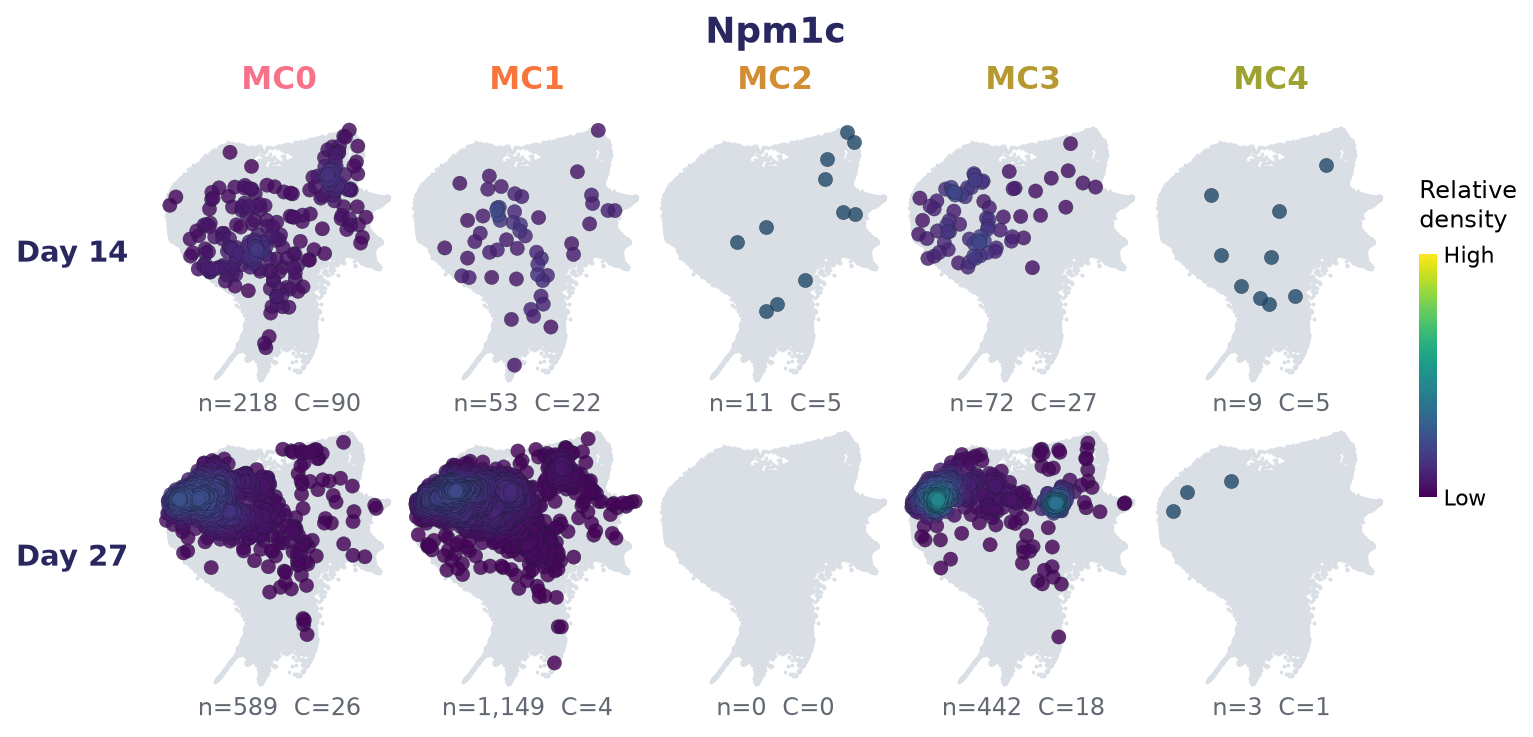

/path/to/ChronoClone/analysis_workspace/singh/singh_figure2b_grid_layout_20260911/panels/atlas_npm1c_block_01.svg


In [16]:

# One authorized faceted figure: all calculations and full construction visible.
stem='atlas_npm1c_block_01';metaclones=[0, 1, 2, 3, 4];arms=['Npm1c'];days=['D14', 'D27'];column_dimension='mc'
columns=metaclones if column_dimension=='mc' else arms
nc=len(columns);nr=len(days)
previous_figures=set(plt.get_fignums())
fw=1.05+1.55*nc+0.95;fh=0.8+1.90*nr
fig=plt.figure(figsize=(fw,fh),dpi=160,facecolor='white')
labels=[];axes_records=[]
group_label=arms[0] if column_dimension=='mc' else f'MC{metaclones[0]}'
labels.append(fig.text((1.05+1.55*nc/2)/fw,1-0.12/fh,group_label,
                      ha='center',va='top',fontsize=16,fontweight='bold',
                      color='#29275f' if column_dimension=='mc' else MC_LABEL_COLORS[metaclones[0]]))
for j,column in enumerate(columns):
    label=f'MC{column}' if column_dimension=='mc' else column
    labels.append(fig.text((1.05+1.55*(j+.5))/fw,1-0.43/fh,label,
                 ha='center',va='top',fontsize=14,fontweight='bold',
                 color=MC_LABEL_COLORS[column] if column_dimension=='mc' else '#29275f'))
for i,day in enumerate(days):
    bottom=fh-0.8-1.9*(i+1)+0.26
    labels.append(fig.text(0.88/fw,(bottom+.83)/fh,'Day '+day[1:],ha='right',va='center',
                          fontsize=13,fontweight='bold',color='#29275f'))
    for j,column in enumerate(columns):
        mc=column if column_dimension=='mc' else metaclones[0]
        arm=arms[0] if column_dimension=='mc' else column
        selected=cells.loc[cells.mc.eq(mc)&cells.arm.eq(arm)&cells.day.eq(day)].copy()
        n=len(selected);family_count=selected.clone.nunique()
        eligible=n>=MIN_DENSITY_CELLS and family_count>=MIN_DENSITY_FAMILIES
        locked=scale_table.loc[scale_table.mc.eq(mc)&scale_table.arm.eq(arm)&scale_table.day.eq(day)].iloc[0]
        assert (n,family_count)==(locked.cells,locked.families)
        if eligible:
            histogram,_,_=np.histogram2d(selected.umap1,selected.umap2,bins=(X_EDGES,Y_EDGES))
            density=gaussian_filter(histogram/n,sigma=(BANDWIDTH/DX,BANDWIDTH/DY),mode='constant',truncate=4)/(DX*DY)
            assert np.isclose(density.max(),locked.density_peak,rtol=1e-12)
            assert np.isclose(density.sum()*DX*DY,locked.density_integrated_mass,rtol=1e-12)
            point_density=map_coordinates(density,np.vstack(((selected.umap1-X_CENTERS[0])/DX,(selected.umap2-Y_CENTERS[0])/DY)),order=1,mode='nearest')
            order=np.argsort(point_density,kind='stable')
        else:
            point_density=None;order=np.arange(n)
        ax=fig.add_axes([(1.05+1.55*j)/fw,bottom/fh,1.52/fw,1.66/fh])
        ax.set_xlim(PLOT_XLIM);ax.set_ylim(PLOT_YLIM);ax.set_aspect('equal');ax.set_axis_off()
        fig.canvas.draw()
        width_pt=ax.get_window_extent().width/fig.dpi*72
        ratio=width_pt/REFERENCE_AXES_WIDTH_PT
        area=15*MARKER_AREA_MULTIPLIER*ratio**2;background_area=2.2*ratio**2;edge=.12*ratio
        assert np.isclose(np.sqrt(area)/width_pt,np.sqrt(15*MARKER_AREA_MULTIPLIER)/REFERENCE_AXES_WIDTH_PT,rtol=1e-12)
        ax.scatter(full_umap[:,0],full_umap[:,1],s=background_area,c='#d9dfe4',
                   linewidths=0,alpha=1,rasterized=True,zorder=0)
        if n:
            kwargs={'c':point_density[order],'cmap':'viridis','norm':DENSITY_NORM} if eligible else {'c':SPARSE_COLOR}
            ax.scatter(selected.umap1.to_numpy()[order],selected.umap2.to_numpy()[order],s=area,
                       **kwargs,edgecolors='#111827',linewidths=edge,alpha=.82,rasterized=False,zorder=2,clip_on=False)
        labels.append(fig.text((1.05+1.55*(j+.5))/fw,(bottom-.035)/fh,f'n={n:,}  C={family_count:,}',
                               ha='center',va='top',fontsize=11,color='#626972'))
        snapshot_records.append({'stem':stem,'mc':mc,'arm':arm,'day':day,'cells':n,'families':family_count,
                                 'representation':locked.representation,'marker_ratio':np.sqrt(area)/width_pt,
                                 'density_peak':float(locked.density_peak)})
        axes_records.append(ax)
# Integral common-scale key, not a separate analytical panel.
bar=fig.add_axes([(1.05+1.55*nc+.15)/fw,.32,.11/fw,.33])
cb=fig.colorbar(plt.cm.ScalarMappable(norm=DENSITY_NORM,cmap='viridis'),cax=bar)
cb.set_ticks([0,DENSITY_MAX]);cb.set_ticklabels(['Low','High']);cb.ax.tick_params(labelsize=10,length=0,pad=3)
cb.outline.set_visible(False)
labels.append(fig.text((1.05+1.55*nc+.15)/fw,.675,'Relative\ndensity',fontsize=11,ha='left',va='bottom'))
fig.canvas.draw()
renderer=fig.canvas.get_renderer()
for label in labels:
    box=label.get_window_extent(renderer)
    assert box.x0>=0 and box.y0>=0 and box.x1<=fig.bbox.width and box.y1<=fig.bbox.height,(stem,label.get_text(),box)
assert set(plt.get_fignums())-previous_figures=={fig.number}
svg=OUT/'panels'/f'{stem}.svg';png=svg.with_suffix('.png')
fig.savefig(svg);fig.savefig(png,dpi=240)
display(fig);plt.close(fig)
grid_records.append({'stem':stem,'columns':columns,'days':days,'column_dimension':column_dimension,
                     'width_in':fw,'height_in':fh,'svg_sha256':sha256(svg),'png_sha256':sha256(png)})
print(svg)


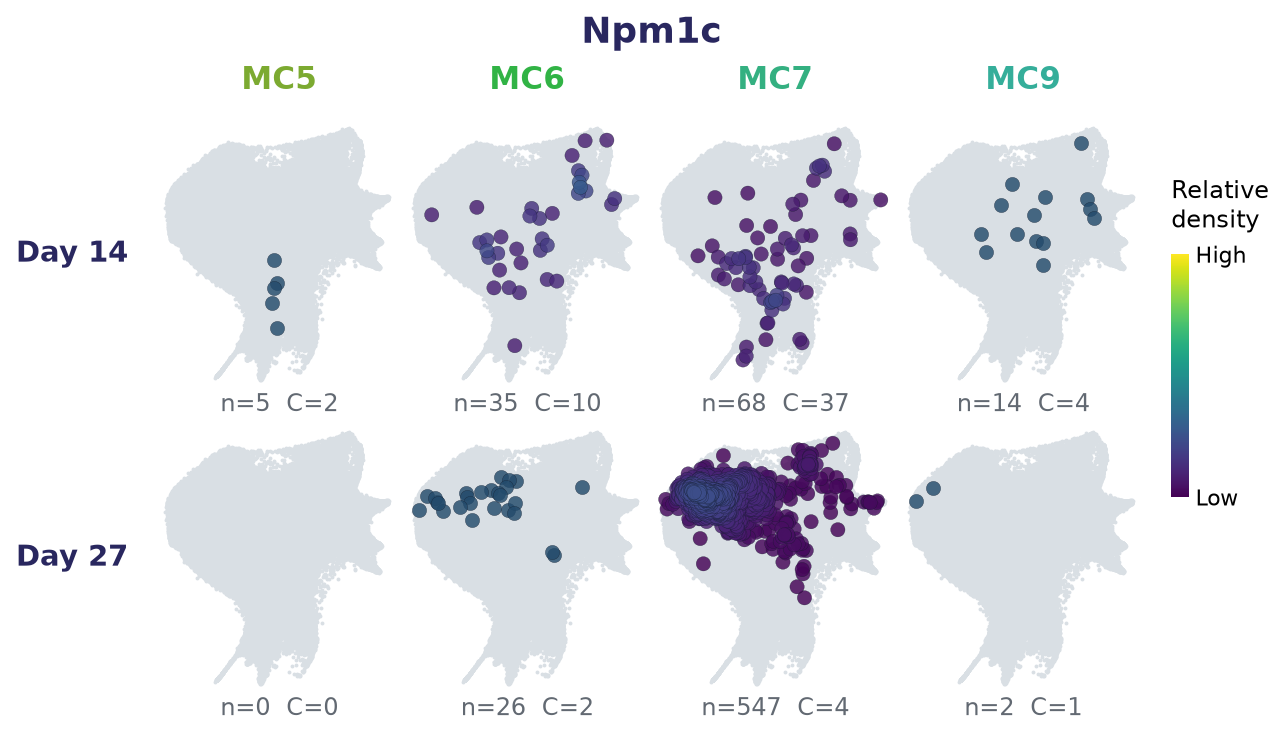

/path/to/ChronoClone/analysis_workspace/singh/singh_figure2b_grid_layout_20260911/panels/atlas_npm1c_block_02.svg


In [17]:

# One authorized faceted figure: all calculations and full construction visible.
stem='atlas_npm1c_block_02';metaclones=[5, 6, 7, 9];arms=['Npm1c'];days=['D14', 'D27'];column_dimension='mc'
columns=metaclones if column_dimension=='mc' else arms
nc=len(columns);nr=len(days)
previous_figures=set(plt.get_fignums())
fw=1.05+1.55*nc+0.95;fh=0.8+1.90*nr
fig=plt.figure(figsize=(fw,fh),dpi=160,facecolor='white')
labels=[];axes_records=[]
group_label=arms[0] if column_dimension=='mc' else f'MC{metaclones[0]}'
labels.append(fig.text((1.05+1.55*nc/2)/fw,1-0.12/fh,group_label,
                      ha='center',va='top',fontsize=16,fontweight='bold',
                      color='#29275f' if column_dimension=='mc' else MC_LABEL_COLORS[metaclones[0]]))
for j,column in enumerate(columns):
    label=f'MC{column}' if column_dimension=='mc' else column
    labels.append(fig.text((1.05+1.55*(j+.5))/fw,1-0.43/fh,label,
                 ha='center',va='top',fontsize=14,fontweight='bold',
                 color=MC_LABEL_COLORS[column] if column_dimension=='mc' else '#29275f'))
for i,day in enumerate(days):
    bottom=fh-0.8-1.9*(i+1)+0.26
    labels.append(fig.text(0.88/fw,(bottom+.83)/fh,'Day '+day[1:],ha='right',va='center',
                          fontsize=13,fontweight='bold',color='#29275f'))
    for j,column in enumerate(columns):
        mc=column if column_dimension=='mc' else metaclones[0]
        arm=arms[0] if column_dimension=='mc' else column
        selected=cells.loc[cells.mc.eq(mc)&cells.arm.eq(arm)&cells.day.eq(day)].copy()
        n=len(selected);family_count=selected.clone.nunique()
        eligible=n>=MIN_DENSITY_CELLS and family_count>=MIN_DENSITY_FAMILIES
        locked=scale_table.loc[scale_table.mc.eq(mc)&scale_table.arm.eq(arm)&scale_table.day.eq(day)].iloc[0]
        assert (n,family_count)==(locked.cells,locked.families)
        if eligible:
            histogram,_,_=np.histogram2d(selected.umap1,selected.umap2,bins=(X_EDGES,Y_EDGES))
            density=gaussian_filter(histogram/n,sigma=(BANDWIDTH/DX,BANDWIDTH/DY),mode='constant',truncate=4)/(DX*DY)
            assert np.isclose(density.max(),locked.density_peak,rtol=1e-12)
            assert np.isclose(density.sum()*DX*DY,locked.density_integrated_mass,rtol=1e-12)
            point_density=map_coordinates(density,np.vstack(((selected.umap1-X_CENTERS[0])/DX,(selected.umap2-Y_CENTERS[0])/DY)),order=1,mode='nearest')
            order=np.argsort(point_density,kind='stable')
        else:
            point_density=None;order=np.arange(n)
        ax=fig.add_axes([(1.05+1.55*j)/fw,bottom/fh,1.52/fw,1.66/fh])
        ax.set_xlim(PLOT_XLIM);ax.set_ylim(PLOT_YLIM);ax.set_aspect('equal');ax.set_axis_off()
        fig.canvas.draw()
        width_pt=ax.get_window_extent().width/fig.dpi*72
        ratio=width_pt/REFERENCE_AXES_WIDTH_PT
        area=15*MARKER_AREA_MULTIPLIER*ratio**2;background_area=2.2*ratio**2;edge=.12*ratio
        assert np.isclose(np.sqrt(area)/width_pt,np.sqrt(15*MARKER_AREA_MULTIPLIER)/REFERENCE_AXES_WIDTH_PT,rtol=1e-12)
        ax.scatter(full_umap[:,0],full_umap[:,1],s=background_area,c='#d9dfe4',
                   linewidths=0,alpha=1,rasterized=True,zorder=0)
        if n:
            kwargs={'c':point_density[order],'cmap':'viridis','norm':DENSITY_NORM} if eligible else {'c':SPARSE_COLOR}
            ax.scatter(selected.umap1.to_numpy()[order],selected.umap2.to_numpy()[order],s=area,
                       **kwargs,edgecolors='#111827',linewidths=edge,alpha=.82,rasterized=False,zorder=2,clip_on=False)
        labels.append(fig.text((1.05+1.55*(j+.5))/fw,(bottom-.035)/fh,f'n={n:,}  C={family_count:,}',
                               ha='center',va='top',fontsize=11,color='#626972'))
        snapshot_records.append({'stem':stem,'mc':mc,'arm':arm,'day':day,'cells':n,'families':family_count,
                                 'representation':locked.representation,'marker_ratio':np.sqrt(area)/width_pt,
                                 'density_peak':float(locked.density_peak)})
        axes_records.append(ax)
# Integral common-scale key, not a separate analytical panel.
bar=fig.add_axes([(1.05+1.55*nc+.15)/fw,.32,.11/fw,.33])
cb=fig.colorbar(plt.cm.ScalarMappable(norm=DENSITY_NORM,cmap='viridis'),cax=bar)
cb.set_ticks([0,DENSITY_MAX]);cb.set_ticklabels(['Low','High']);cb.ax.tick_params(labelsize=10,length=0,pad=3)
cb.outline.set_visible(False)
labels.append(fig.text((1.05+1.55*nc+.15)/fw,.675,'Relative\ndensity',fontsize=11,ha='left',va='bottom'))
fig.canvas.draw()
renderer=fig.canvas.get_renderer()
for label in labels:
    box=label.get_window_extent(renderer)
    assert box.x0>=0 and box.y0>=0 and box.x1<=fig.bbox.width and box.y1<=fig.bbox.height,(stem,label.get_text(),box)
assert set(plt.get_fignums())-previous_figures=={fig.number}
svg=OUT/'panels'/f'{stem}.svg';png=svg.with_suffix('.png')
fig.savefig(svg);fig.savefig(png,dpi=240)
display(fig);plt.close(fig)
grid_records.append({'stem':stem,'columns':columns,'days':days,'column_dimension':column_dimension,
                     'width_in':fw,'height_in':fh,'svg_sha256':sha256(svg),'png_sha256':sha256(png)})
print(svg)


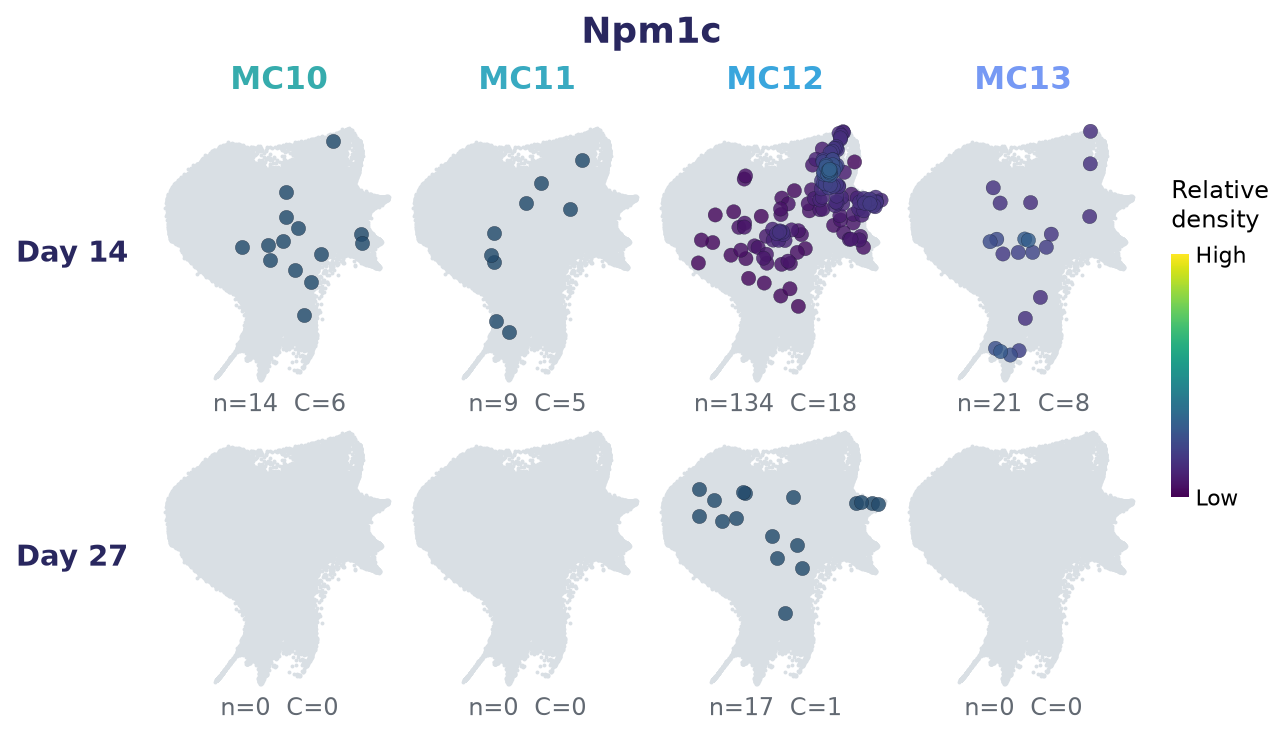

/path/to/ChronoClone/analysis_workspace/singh/singh_figure2b_grid_layout_20260911/panels/atlas_npm1c_block_03.svg


In [18]:

# One authorized faceted figure: all calculations and full construction visible.
stem='atlas_npm1c_block_03';metaclones=[10, 11, 12, 13];arms=['Npm1c'];days=['D14', 'D27'];column_dimension='mc'
columns=metaclones if column_dimension=='mc' else arms
nc=len(columns);nr=len(days)
previous_figures=set(plt.get_fignums())
fw=1.05+1.55*nc+0.95;fh=0.8+1.90*nr
fig=plt.figure(figsize=(fw,fh),dpi=160,facecolor='white')
labels=[];axes_records=[]
group_label=arms[0] if column_dimension=='mc' else f'MC{metaclones[0]}'
labels.append(fig.text((1.05+1.55*nc/2)/fw,1-0.12/fh,group_label,
                      ha='center',va='top',fontsize=16,fontweight='bold',
                      color='#29275f' if column_dimension=='mc' else MC_LABEL_COLORS[metaclones[0]]))
for j,column in enumerate(columns):
    label=f'MC{column}' if column_dimension=='mc' else column
    labels.append(fig.text((1.05+1.55*(j+.5))/fw,1-0.43/fh,label,
                 ha='center',va='top',fontsize=14,fontweight='bold',
                 color=MC_LABEL_COLORS[column] if column_dimension=='mc' else '#29275f'))
for i,day in enumerate(days):
    bottom=fh-0.8-1.9*(i+1)+0.26
    labels.append(fig.text(0.88/fw,(bottom+.83)/fh,'Day '+day[1:],ha='right',va='center',
                          fontsize=13,fontweight='bold',color='#29275f'))
    for j,column in enumerate(columns):
        mc=column if column_dimension=='mc' else metaclones[0]
        arm=arms[0] if column_dimension=='mc' else column
        selected=cells.loc[cells.mc.eq(mc)&cells.arm.eq(arm)&cells.day.eq(day)].copy()
        n=len(selected);family_count=selected.clone.nunique()
        eligible=n>=MIN_DENSITY_CELLS and family_count>=MIN_DENSITY_FAMILIES
        locked=scale_table.loc[scale_table.mc.eq(mc)&scale_table.arm.eq(arm)&scale_table.day.eq(day)].iloc[0]
        assert (n,family_count)==(locked.cells,locked.families)
        if eligible:
            histogram,_,_=np.histogram2d(selected.umap1,selected.umap2,bins=(X_EDGES,Y_EDGES))
            density=gaussian_filter(histogram/n,sigma=(BANDWIDTH/DX,BANDWIDTH/DY),mode='constant',truncate=4)/(DX*DY)
            assert np.isclose(density.max(),locked.density_peak,rtol=1e-12)
            assert np.isclose(density.sum()*DX*DY,locked.density_integrated_mass,rtol=1e-12)
            point_density=map_coordinates(density,np.vstack(((selected.umap1-X_CENTERS[0])/DX,(selected.umap2-Y_CENTERS[0])/DY)),order=1,mode='nearest')
            order=np.argsort(point_density,kind='stable')
        else:
            point_density=None;order=np.arange(n)
        ax=fig.add_axes([(1.05+1.55*j)/fw,bottom/fh,1.52/fw,1.66/fh])
        ax.set_xlim(PLOT_XLIM);ax.set_ylim(PLOT_YLIM);ax.set_aspect('equal');ax.set_axis_off()
        fig.canvas.draw()
        width_pt=ax.get_window_extent().width/fig.dpi*72
        ratio=width_pt/REFERENCE_AXES_WIDTH_PT
        area=15*MARKER_AREA_MULTIPLIER*ratio**2;background_area=2.2*ratio**2;edge=.12*ratio
        assert np.isclose(np.sqrt(area)/width_pt,np.sqrt(15*MARKER_AREA_MULTIPLIER)/REFERENCE_AXES_WIDTH_PT,rtol=1e-12)
        ax.scatter(full_umap[:,0],full_umap[:,1],s=background_area,c='#d9dfe4',
                   linewidths=0,alpha=1,rasterized=True,zorder=0)
        if n:
            kwargs={'c':point_density[order],'cmap':'viridis','norm':DENSITY_NORM} if eligible else {'c':SPARSE_COLOR}
            ax.scatter(selected.umap1.to_numpy()[order],selected.umap2.to_numpy()[order],s=area,
                       **kwargs,edgecolors='#111827',linewidths=edge,alpha=.82,rasterized=False,zorder=2,clip_on=False)
        labels.append(fig.text((1.05+1.55*(j+.5))/fw,(bottom-.035)/fh,f'n={n:,}  C={family_count:,}',
                               ha='center',va='top',fontsize=11,color='#626972'))
        snapshot_records.append({'stem':stem,'mc':mc,'arm':arm,'day':day,'cells':n,'families':family_count,
                                 'representation':locked.representation,'marker_ratio':np.sqrt(area)/width_pt,
                                 'density_peak':float(locked.density_peak)})
        axes_records.append(ax)
# Integral common-scale key, not a separate analytical panel.
bar=fig.add_axes([(1.05+1.55*nc+.15)/fw,.32,.11/fw,.33])
cb=fig.colorbar(plt.cm.ScalarMappable(norm=DENSITY_NORM,cmap='viridis'),cax=bar)
cb.set_ticks([0,DENSITY_MAX]);cb.set_ticklabels(['Low','High']);cb.ax.tick_params(labelsize=10,length=0,pad=3)
cb.outline.set_visible(False)
labels.append(fig.text((1.05+1.55*nc+.15)/fw,.675,'Relative\ndensity',fontsize=11,ha='left',va='bottom'))
fig.canvas.draw()
renderer=fig.canvas.get_renderer()
for label in labels:
    box=label.get_window_extent(renderer)
    assert box.x0>=0 and box.y0>=0 and box.x1<=fig.bbox.width and box.y1<=fig.bbox.height,(stem,label.get_text(),box)
assert set(plt.get_fignums())-previous_figures=={fig.number}
svg=OUT/'panels'/f'{stem}.svg';png=svg.with_suffix('.png')
fig.savefig(svg);fig.savefig(png,dpi=240)
display(fig);plt.close(fig)
grid_records.append({'stem':stem,'columns':columns,'days':days,'column_dimension':column_dimension,
                     'width_in':fw,'height_in':fh,'svg_sha256':sha256(svg),'png_sha256':sha256(png)})
print(svg)


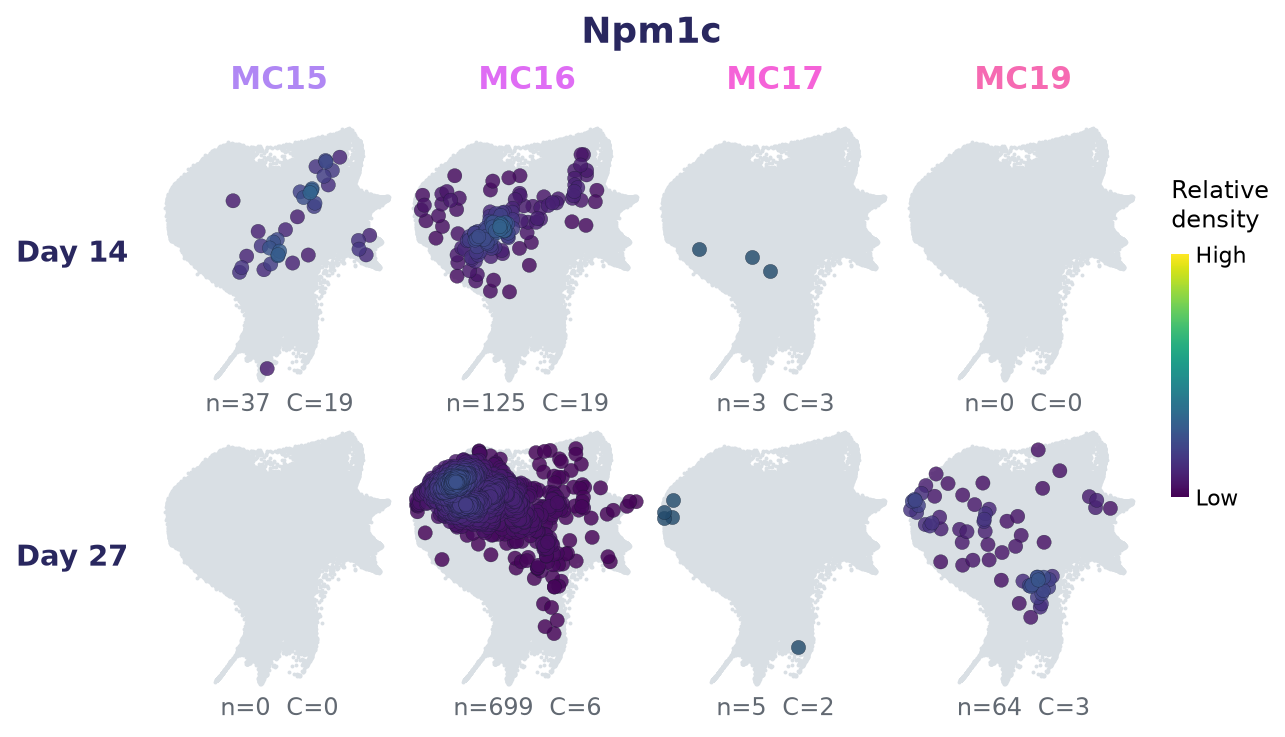

/path/to/ChronoClone/analysis_workspace/singh/singh_figure2b_grid_layout_20260911/panels/atlas_npm1c_block_04.svg


In [19]:

# One authorized faceted figure: all calculations and full construction visible.
stem='atlas_npm1c_block_04';metaclones=[15, 16, 17, 19];arms=['Npm1c'];days=['D14', 'D27'];column_dimension='mc'
columns=metaclones if column_dimension=='mc' else arms
nc=len(columns);nr=len(days)
previous_figures=set(plt.get_fignums())
fw=1.05+1.55*nc+0.95;fh=0.8+1.90*nr
fig=plt.figure(figsize=(fw,fh),dpi=160,facecolor='white')
labels=[];axes_records=[]
group_label=arms[0] if column_dimension=='mc' else f'MC{metaclones[0]}'
labels.append(fig.text((1.05+1.55*nc/2)/fw,1-0.12/fh,group_label,
                      ha='center',va='top',fontsize=16,fontweight='bold',
                      color='#29275f' if column_dimension=='mc' else MC_LABEL_COLORS[metaclones[0]]))
for j,column in enumerate(columns):
    label=f'MC{column}' if column_dimension=='mc' else column
    labels.append(fig.text((1.05+1.55*(j+.5))/fw,1-0.43/fh,label,
                 ha='center',va='top',fontsize=14,fontweight='bold',
                 color=MC_LABEL_COLORS[column] if column_dimension=='mc' else '#29275f'))
for i,day in enumerate(days):
    bottom=fh-0.8-1.9*(i+1)+0.26
    labels.append(fig.text(0.88/fw,(bottom+.83)/fh,'Day '+day[1:],ha='right',va='center',
                          fontsize=13,fontweight='bold',color='#29275f'))
    for j,column in enumerate(columns):
        mc=column if column_dimension=='mc' else metaclones[0]
        arm=arms[0] if column_dimension=='mc' else column
        selected=cells.loc[cells.mc.eq(mc)&cells.arm.eq(arm)&cells.day.eq(day)].copy()
        n=len(selected);family_count=selected.clone.nunique()
        eligible=n>=MIN_DENSITY_CELLS and family_count>=MIN_DENSITY_FAMILIES
        locked=scale_table.loc[scale_table.mc.eq(mc)&scale_table.arm.eq(arm)&scale_table.day.eq(day)].iloc[0]
        assert (n,family_count)==(locked.cells,locked.families)
        if eligible:
            histogram,_,_=np.histogram2d(selected.umap1,selected.umap2,bins=(X_EDGES,Y_EDGES))
            density=gaussian_filter(histogram/n,sigma=(BANDWIDTH/DX,BANDWIDTH/DY),mode='constant',truncate=4)/(DX*DY)
            assert np.isclose(density.max(),locked.density_peak,rtol=1e-12)
            assert np.isclose(density.sum()*DX*DY,locked.density_integrated_mass,rtol=1e-12)
            point_density=map_coordinates(density,np.vstack(((selected.umap1-X_CENTERS[0])/DX,(selected.umap2-Y_CENTERS[0])/DY)),order=1,mode='nearest')
            order=np.argsort(point_density,kind='stable')
        else:
            point_density=None;order=np.arange(n)
        ax=fig.add_axes([(1.05+1.55*j)/fw,bottom/fh,1.52/fw,1.66/fh])
        ax.set_xlim(PLOT_XLIM);ax.set_ylim(PLOT_YLIM);ax.set_aspect('equal');ax.set_axis_off()
        fig.canvas.draw()
        width_pt=ax.get_window_extent().width/fig.dpi*72
        ratio=width_pt/REFERENCE_AXES_WIDTH_PT
        area=15*MARKER_AREA_MULTIPLIER*ratio**2;background_area=2.2*ratio**2;edge=.12*ratio
        assert np.isclose(np.sqrt(area)/width_pt,np.sqrt(15*MARKER_AREA_MULTIPLIER)/REFERENCE_AXES_WIDTH_PT,rtol=1e-12)
        ax.scatter(full_umap[:,0],full_umap[:,1],s=background_area,c='#d9dfe4',
                   linewidths=0,alpha=1,rasterized=True,zorder=0)
        if n:
            kwargs={'c':point_density[order],'cmap':'viridis','norm':DENSITY_NORM} if eligible else {'c':SPARSE_COLOR}
            ax.scatter(selected.umap1.to_numpy()[order],selected.umap2.to_numpy()[order],s=area,
                       **kwargs,edgecolors='#111827',linewidths=edge,alpha=.82,rasterized=False,zorder=2,clip_on=False)
        labels.append(fig.text((1.05+1.55*(j+.5))/fw,(bottom-.035)/fh,f'n={n:,}  C={family_count:,}',
                               ha='center',va='top',fontsize=11,color='#626972'))
        snapshot_records.append({'stem':stem,'mc':mc,'arm':arm,'day':day,'cells':n,'families':family_count,
                                 'representation':locked.representation,'marker_ratio':np.sqrt(area)/width_pt,
                                 'density_peak':float(locked.density_peak)})
        axes_records.append(ax)
# Integral common-scale key, not a separate analytical panel.
bar=fig.add_axes([(1.05+1.55*nc+.15)/fw,.32,.11/fw,.33])
cb=fig.colorbar(plt.cm.ScalarMappable(norm=DENSITY_NORM,cmap='viridis'),cax=bar)
cb.set_ticks([0,DENSITY_MAX]);cb.set_ticklabels(['Low','High']);cb.ax.tick_params(labelsize=10,length=0,pad=3)
cb.outline.set_visible(False)
labels.append(fig.text((1.05+1.55*nc+.15)/fw,.675,'Relative\ndensity',fontsize=11,ha='left',va='bottom'))
fig.canvas.draw()
renderer=fig.canvas.get_renderer()
for label in labels:
    box=label.get_window_extent(renderer)
    assert box.x0>=0 and box.y0>=0 and box.x1<=fig.bbox.width and box.y1<=fig.bbox.height,(stem,label.get_text(),box)
assert set(plt.get_fignums())-previous_figures=={fig.number}
svg=OUT/'panels'/f'{stem}.svg';png=svg.with_suffix('.png')
fig.savefig(svg);fig.savefig(png,dpi=240)
display(fig);plt.close(fig)
grid_records.append({'stem':stem,'columns':columns,'days':days,'column_dimension':column_dimension,
                     'width_in':fw,'height_in':fh,'svg_sha256':sha256(svg),'png_sha256':sha256(png)})
print(svg)


In [20]:

grid_table=pd.DataFrame(grid_records);snapshots=pd.DataFrame(snapshot_records)
complete=snapshots.loc[snapshots.stem.str.startswith('atlas_')].copy()
assert len(grid_table)==15 and len(complete)==119
assert not complete[['mc','arm','day']].duplicated().any()
comparison=complete.sort_values(['mc','arm','day']).reset_index(drop=True)
expected=scale_table.sort_values(['mc','arm','day']).reset_index(drop=True)
pd.testing.assert_frame_equal(comparison[['mc','arm','day','cells','families','representation']],expected[['mc','arm','day','cells','families','representation']])
assert not complete.loc[complete.day.eq('D7'),'arm'].ne('WT').any()
assert np.allclose(snapshots.marker_ratio,np.sqrt(15*MARKER_AREA_MULTIPLIER)/REFERENCE_AXES_WIDTH_PT,rtol=1e-12)
grid_table.to_json(OUT/'tables/grid_manifest.json',orient='records',indent=2)
snapshots.to_csv(OUT/'tables/grid_snapshot_manifest.csv',index=False)
qc={'complete_atlas_snapshots':len(complete),'grid_figures':len(grid_table),'same_cohort_counts':True,
    'same_coordinates':True,'same_density_estimates_and_common_scale':True,'consistent_marker_proportions_across_grids':True,
    'foreground_area_multiplier_over_figure2b':MARKER_AREA_MULTIPLIER,
    'day7_only_wt':True,'no_new_inference':True,'visual_review':'pending individual review'}
(OUT/'reports/grid_integrity.json').write_text(json.dumps(qc,indent=2))
display(grid_table);display(qc)


,stem,columns,days,column_dimension,width_in,height_in,svg_sha256,png_sha256
0,figure_5d_wt_histories_grid,"[0, 3, 7]","[D7, D14, D27]",mc,6.65,6.5,73e9447e2bf367b3cc1acba126dacd0c751e8c223bf7aa...,5181513bf0244e461c4ae163f8e7015eb09835f9545ab5...
1,figure_6c_mc03_condition_grid,"[WT, Dnmt3a, Npm1c]","[D14, D27]",arm,6.65,4.6,ff913bf7771f0cfbbdc11ea8b819b8d60eafdf16fc01db...,9e7dce88e42aa9c13c3cc52efbed21d23d3319e3c2e391...
2,figure_6g_mc00_condition_grid,"[WT, Dnmt3a, Npm1c]","[D14, D27]",arm,6.65,4.6,11d3555983186eaab9162570ae5884f960ae174a0e93ca...,6a532a6bf6d99f21ed45ed0a1284f98cc833db5188fbc4...
3,atlas_wt_block_01,"[0, 1, 2, 3, 4]","[D7, D14, D27]",mc,9.75,6.5,d4703131aa7a158aa56a36563dec9ec7201856a190b023...,9de19df70cd98a01d4c2bdc262f61ee263f307b8d3d45f...
4,atlas_wt_block_02,"[5, 6, 7, 9]","[D7, D14, D27]",mc,8.20,6.5,e0ab8dfe63f83eb5e37b49c9b2422dbcae9d7611ebfbee...,bee2e70503c215354da5d18ff6eac89b3e12499a2eeac6...
5,atlas_wt_block_03,"[10, 11, 12, 13]","[D7, D14, D27]",mc,8.20,6.5,98053496cb89d5ed2cffeedb3350be1292c08dd9cc12fa...,54adf2fe5355109962f498c6bcab338b8fc793bf84c760...
6,atlas_wt_block_04,"[15, 16, 17, 19]","[D7, D14, D27]",mc,8.20,6.5,edc29b9b03176e3a76a634eb6a149704c9a1885fdd70dc...,accc18a4d4524dc22aa5869f29c44f27e9c1484c4775a3...
7,atlas_dnmt3a_block_01,"[0, 1, 2, 3, 4]","[D14, D27]",mc,9.75,4.6,61a8267ff4a3e5529e79c9009ef5b2ab9d22e2bfc147f3...,27a623b422b1267cba105476424601d0c5e3b51130d21f...
8,atlas_dnmt3a_block_02,"[5, 6, 7, 9]","[D14, D27]",mc,8.20,4.6,b5cec25517c858d2049215c2f4412b731a5bed69ce1882...,1c9f0600bab47c1987d2ee8977b2a30b385c135b890f67...
9,atlas_dnmt3a_block_03,"[10, 11, 12, 13]","[D14, D27]",mc,8.20,4.6,b920603833db15fd8204618862ddb812d88f4a4cb8b425...,f4638faded01c193de02ad59c12b98562fff31cf06c07d...


{'complete_atlas_snapshots': 119,
 'grid_figures': 15,
 'same_cohort_counts': True,
 'same_coordinates': True,
 'same_density_estimates_and_common_scale': True,
 'consistent_marker_proportions_across_grids': True,
 'foreground_area_multiplier_over_figure2b': 2.0,
 'day7_only_wt': True,
 'no_new_inference': True,
 'visual_review': 'pending individual review'}